# Artifact Denoising — Wavelet, ASR, Cascade, and Autoencoder

Per-subject denoising of the raw EEG windows in `windows_raw.pkl`. Four methods
are compared on the six artifact classes:

1. **Wavelet** — per-channel discrete wavelet soft-thresholding (`db4`, level 5).
2. **ASR** — Artifact Subspace Reconstruction, calibrated on each subject's rest.
3. **Wavelet + ASR** — wavelet denoise cascaded into ASR.
4. **Autoencoder** — a residual-learning 1D conv autoencoder that learns an
   artifact-specific subtraction (`x - decoder(encoder(x))`).

There is **no ground-truth clean signal**, so every metric is measured *relative
to a per-subject rest reference* (mean RMS and mean Welch PSD across that
subject's rest windows). Three metrics are reported per method: artifact-band
power reduction (%), neural-band (8–30 Hz) retention (%), and RMS reduction (%)
relative to rest. All visualizations use the **median-RMS** window (never a
best/worst case) to avoid cherry-picking.

## Section 0 — Imports, configuration, and data loading

In [1]:
import pickle
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import pywt
from meegkit.asr import ASR
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# --- meegkit 0.1.9 + NumPy 2.x compatibility shim ------------------------
# fit_eeg_distribution returns 1-element arrays for (mu, sig, alpha); under
# NumPy 2.x asr_calibrate's per-channel `mu[ichan] = ...` assignment then
# raises "setting an array element with a sequence". Wrap it to return plain
# scalars. We source the original from the *defining* module
# (meegkit.utils.asr), which is never patched, so re-running this cell can
# never wrap an already-wrapped function -> no RecursionError.
import meegkit.asr as _mkasr
import meegkit.utils.asr as _mkasr_utils
_orig_fit_eeg = _mkasr_utils.fit_eeg_distribution   # pristine, never patched
def _scalar_fit_eeg(*args, **kwargs):
    mu, sig, alpha, beta = _orig_fit_eeg(*args, **kwargs)
    _s = lambda v: float(np.ravel(v)[0])
    return _s(mu), _s(sig), _s(alpha), _s(beta)
_mkasr.fit_eeg_distribution = _scalar_fit_eeg

# NumPy 2.x renamed np.trapz -> np.trapezoid; alias keeps the metrics working
# on either version.
_trapz = getattr(np, "trapezoid", getattr(np, "trapz", None))

CONFIG = {
    "DATA_DIR":        Path("processed_xdf"),
    "OUTPUT_DIR":      Path("processed_xdf/07_Denoising_plots"),
    "SFREQ":           250,
    "WINDOW_SAMPLES":  500,
    "STEP_SAMPLES":    125,
    "CALIB_WINDOWS":   15,
    "ASR_CUTOFF":      9,
    "WAVELET":         "db4",
    "WAVELET_LEVEL":   5,
    "NEURAL_BAND":     (8, 30),
    "ARTIFACT_BAND":   (0.5, 8),
    "CLENCH_BAND":     (30, 99),
    "AE_EPOCHS":       20,
    "AE_BATCH_SIZE":   32,
    "AE_LR":           5e-4,
    "AE_WEIGHT_DECAY": 1e-3,
    "AE_VAL_SPLIT":    0.2,
    "REPR_SUBJECTS": [
        "sub-0b11bec3",
        #"sub-b835837a",
        #"sub-d0bb067d",
    ],
    "RANDOM_STATE":    42,
}

ARTIFACT_CLASSES = ["blink", "look_left", "look_right", "horiz_head", "vert_head", "clench"]
METHODS = ["wavelet", "asr", "wavelet_asr", "autoencoder"]

METHOD_COLORS = {
    "raw":         "grey",
    "wavelet":     "steelblue",
    "asr":         "darkorange",
    "wavelet_asr": "green",
    "autoencoder": "purple",
    "rest_ref":    "black",
}
METHOD_LABELS = {
    "raw":         "raw",
    "wavelet":     "Wavelet",
    "asr":         "ASR",
    "wavelet_asr": "Wavelet+ASR",
    "autoencoder": "Autoencoder",
    "rest_ref":    "rest ref",
}

np.random.seed(CONFIG["RANDOM_STATE"])
torch.manual_seed(CONFIG["RANDOM_STATE"])
device = torch.device("cuda" if torch.cuda.is_available() else
                      ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Torch device: {device}")

# ---- Load raw windows (denoising operates on the raw signal, not features) ----
windows_path  = CONFIG["DATA_DIR"] / "windows_raw.pkl"
features_path = CONFIG["DATA_DIR"] / "features.pkl"
print(f"Loading {windows_path}")
with windows_path.open("rb") as f:
    raw_bundle = pickle.load(f)

X_raw       = raw_bundle["windows_raw"].astype(np.float64)   # (n_windows, 4, 500)
y           = np.asarray(raw_bundle["y_fine"])
subject_ids = np.asarray(raw_bundle["subject_ids"])

# features.pkl is loaded only to cross-check alignment with the raw windows.
print(f"Loading {features_path}")
with features_path.open("rb") as f:
    feat_bundle = pickle.load(f)
assert np.array_equal(feat_bundle["subject_ids"], subject_ids), \
    "subject_ids mismatch between features.pkl and windows_raw.pkl"

N_CHANNELS = X_raw.shape[1]
SUBJECTS   = sorted(np.unique(subject_ids).tolist())

print(f"X_raw.shape       : {X_raw.shape}  dtype={X_raw.dtype}")
print(f"y.shape           : {y.shape}  classes={sorted(np.unique(y))}")
print(f"subject_ids.shape : {subject_ids.shape}  n_subjects={len(SUBJECTS)}")
print(f"channels          : {N_CHANNELS}")

print("\nClass distribution:")
vc = pd.Series(y).value_counts()
print(pd.DataFrame({"count": vc, "pct": (vc / vc.sum() * 100).round(1)}).to_string())

Torch device: cuda
Loading processed_xdf\windows_raw.pkl
Loading processed_xdf\features.pkl
X_raw.shape       : (11418, 4, 500)  dtype=float64
y.shape           : (11418,)  classes=['blink', 'clench', 'horiz_head', 'look_left', 'look_right', 'rest', 'vert_head']
subject_ids.shape : (11418,)  n_subjects=13
channels          : 4

Class distribution:
            count   pct
rest         5511  48.3
blink         988   8.7
look_left     988   8.7
look_right    987   8.6
vert_head     987   8.6
horiz_head    987   8.6
clench        970   8.5


## Section 0.1 — Temporal ordering assertion

ASR calibration and the autoencoder's mean-rest target both assume each
subject's windows are stored in **recording order**. There is no explicit
timestamp array, so we verify ordering *indirectly*: the global row positions of
a subject's windows must be a contiguous, monotonically increasing block. This
is asserted per subject before any slicing.

In [2]:
# Section 0.1 — Verify each subject's windows are in temporal (recording) order.
for subj in SUBJECTS:
    subj_idx = np.where(subject_ids == subj)[0]
    assert subj_idx.size > 0, f"{subj}: no windows found"
    assert np.all(np.diff(subj_idx) > 0), \
        f"{subj}: window indices are not monotonically increasing"
    print(f"  {subj:>16s}  windows={subj_idx.size:4d}  "
          f"idx range=[{subj_idx[0]}, {subj_idx[-1]}]  ordering OK")

print("\nAll subjects: windows are in monotonic temporal order.")

      sub-0b11bec3  windows= 880  idx range=[0, 879]  ordering OK
      sub-123051bf  windows= 881  idx range=[880, 1760]  ordering OK
      sub-160f8068  windows= 880  idx range=[1761, 2640]  ordering OK
      sub-2cbce981  windows= 862  idx range=[2641, 3502]  ordering OK
      sub-3f0ec71e  windows= 870  idx range=[3503, 4372]  ordering OK
      sub-413e6462  windows= 880  idx range=[4373, 5252]  ordering OK
      sub-81091e67  windows= 881  idx range=[5253, 6133]  ordering OK
      sub-9c5349dc  windows= 881  idx range=[6134, 7014]  ordering OK
      sub-b835837a  windows= 880  idx range=[7015, 7894]  ordering OK
      sub-bf3d1a74  windows= 880  idx range=[7895, 8774]  ordering OK
      sub-d0bb067d  windows= 881  idx range=[8775, 9655]  ordering OK
      sub-ece8d790  windows= 881  idx range=[9656, 10536]  ordering OK
      sub-f415eee8  windows= 881  idx range=[10537, 11417]  ordering OK

All subjects: windows are in monotonic temporal order.


## Section 0.2 — Per-subject calibration signal & SNR reference

For each subject we build, once, the two artefacts every later step reuses:

* **Calibration signal** for ASR — 60 s of clean rest built from the *first* and
  *last* 30 s of non-overlapping rest segments (`rest_windows[::4]`, since the
  0.5 s step means every 4th window is contiguous). Taking both ends makes the
  calibration robust to slow drift over the recording.
* **SNR reference** — the per-channel mean RMS and mean Welch PSD across **all**
  of that subject's rest windows.

Welch PSDs use `nperseg=250` (1 s) at `fs=250`.

In [3]:
# Section 0.2 — Per-subject ASR calibration signal + rest SNR reference.
calib_signals = {}     # subj -> (4, 15000) clean calibration signal
snr_ref_rms   = {}     # subj -> (4,)         mean RMS across rest windows
snr_ref_psd   = {}     # subj -> (4, n_freqs) mean Welch PSD across rest windows
welch_freqs   = None   # shared frequency axis (set once)

NPERSEG = CONFIG["SFREQ"]   # 1s segments for Welch

for subj in SUBJECTS:
    rest_idx = np.where((subject_ids == subj) & (y == "rest"))[0]
    assert rest_idx.size > 0, f"{subj}: no rest windows"
    rest_windows = X_raw[rest_idx]            # (n_rest, 4, 500), temporal order

    # Every 4th window is contiguous (0.5s step, 2s window -> 4 steps per window).
    non_overlapping = rest_windows[::4]                  # contiguous 2s segments
    first = non_overlapping[:CONFIG["CALIB_WINDOWS"]]    # (15, 4, 500)
    last  = non_overlapping[-CONFIG["CALIB_WINDOWS"]:]   # (15, 4, 500)
    calib_signal = np.concatenate(
        [first.transpose(1, 0, 2).reshape(N_CHANNELS, -1),
         last.transpose(1, 0, 2).reshape(N_CHANNELS, -1)], axis=-1
    )                                          # (4, 15000) -- 60s of clean signal
    expected = 2 * CONFIG["CALIB_WINDOWS"] * CONFIG["WINDOW_SAMPLES"]
    assert calib_signal.shape == (N_CHANNELS, expected), \
        f"{subj}: calib_signal shape {calib_signal.shape} != (4, {expected})"
    calib_signals[subj] = calib_signal

    # SNR reference -- mean RMS per channel across ALL rest windows.
    snr_ref_rms[subj] = np.sqrt(np.mean(rest_windows ** 2, axis=(0, 2)))   # (4,)

    # SNR reference -- mean Welch PSD per channel across ALL rest windows.
    psd_per_ch = []
    for ch in range(N_CHANNELS):
        f_ax, pxx = signal.welch(rest_windows[:, ch, :], fs=CONFIG["SFREQ"],
                                 nperseg=NPERSEG, axis=-1)   # (n_rest, n_freqs)
        psd_per_ch.append(pxx.mean(axis=0))                  # -> (n_freqs,)
    snr_ref_psd[subj] = np.vstack(psd_per_ch)                # (4, n_freqs)
    if welch_freqs is None:
        welch_freqs = f_ax

    calib_seconds = calib_signal.shape[1] / CONFIG["SFREQ"]
    print(f"  {subj:>16s}  n_rest={rest_windows.shape[0]:4d}  "
          f"calib={calib_seconds:.0f}s  ref_rms={np.round(snr_ref_rms[subj], 2)}")

print(f"\nWelch frequency axis: {welch_freqs.shape[0]} bins, "
      f"{welch_freqs[0]:.1f}-{welch_freqs[-1]:.1f} Hz")

      sub-0b11bec3  n_rest= 424  calib=60s  ref_rms=[3.46 2.83 1.52 1.69]
      sub-123051bf  n_rest= 424  calib=60s  ref_rms=[0.82 1.11 1.11 1.06]
      sub-160f8068  n_rest= 424  calib=60s  ref_rms=[0.93 1.27 0.32 0.28]
      sub-2cbce981  n_rest= 424  calib=60s  ref_rms=[4.15 0.99 5.68 6.62]
      sub-3f0ec71e  n_rest= 420  calib=60s  ref_rms=[2.35 0.78 3.3  0.68]
      sub-413e6462  n_rest= 424  calib=60s  ref_rms=[1.92 1.96 1.83 1.79]
      sub-81091e67  n_rest= 424  calib=60s  ref_rms=[4.   1.05 0.84 1.12]
      sub-9c5349dc  n_rest= 425  calib=60s  ref_rms=[1.12 1.53 0.66 4.53]
      sub-b835837a  n_rest= 424  calib=60s  ref_rms=[1.89 1.15 1.16 1.12]
      sub-bf3d1a74  n_rest= 424  calib=60s  ref_rms=[1.05 1.35 1.3  1.8 ]
      sub-d0bb067d  n_rest= 424  calib=60s  ref_rms=[42.7   2.29  1.23  0.72]
      sub-ece8d790  n_rest= 425  calib=60s  ref_rms=[3.08 1.22 0.92 2.7 ]
      sub-f415eee8  n_rest= 425  calib=60s  ref_rms=[0.39 0.36 0.84 0.38]

Welch frequency axis: 126 bins, 0

## Section 0.3 — Denoising and metric functions

* `wavelet_denoise` — per-channel DWT with universal (VisuShrink) soft
  thresholding; channels are denoised **independently**.
* `fit_asr` / `asr_denoise` — fit ASR on a subject's 60 s calibration signal and
  apply it to single windows.
* `compute_metrics` — artifact-band power reduction, neural-band retention, and
  RMS reduction, all relative to the rest reference. The artifact band is
  `CLENCH_BAND` for clench (high-frequency EMG) and `ARTIFACT_BAND` for the
  low-frequency ocular/head classes.
* `get_representative_window` — returns the **median-RMS** window (never the
  best or worst case).

In [4]:
# Section 0.3 (a) -- Denoising functions.

def wavelet_denoise(window):
    """Per-channel DWT soft-threshold denoising (channels independent).

    Parameters
    ----------
    window : numpy.ndarray
        Single window, shape (4, 500).

    Returns
    -------
    numpy.ndarray
        Denoised window, shape (4, 500).
    """
    out = np.empty_like(window)
    n = window.shape[-1]
    for ch in range(window.shape[0]):
        coeffs = pywt.wavedec(window[ch], CONFIG["WAVELET"],
                              level=CONFIG["WAVELET_LEVEL"])
        # Noise sigma estimated from the finest detail coefficients via MAD.
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745
        # Universal (VisuShrink) threshold: sigma * sqrt(2 ln n).
        thresh = sigma * np.sqrt(2.0 * np.log(n))
        # Soft-threshold every detail level; keep the approximation untouched.
        denoised = [coeffs[0]] + [
            pywt.threshold(c, thresh, mode="soft") for c in coeffs[1:]
        ]
        rec = pywt.waverec(denoised, CONFIG["WAVELET"])
        out[ch] = rec[:n]      # waverec may return n+1 samples -> trim
    return out


def fit_asr(calib_signal, sfreq, cutoff):
    """Fit an ASR model on a subject's clean calibration signal.

    Parameters
    ----------
    calib_signal : numpy.ndarray
        Clean calibration data, shape (4, n_samples).
    sfreq : int
        Sampling frequency in Hz.
    cutoff : float
        ASR rejection cutoff k (standard deviations).

    Returns
    -------
    meegkit.asr.ASR
        Fitted ASR instance.
    """
    asr = ASR(sfreq=sfreq, cutoff=cutoff)
    asr.fit(calib_signal)          # meegkit consumes (n_channels, n_samples)
    return asr


def asr_denoise(window, asr):
    """Apply a fitted ASR model to one window.

    Parameters
    ----------
    window : numpy.ndarray
        Single window, shape (4, 500).
    asr : meegkit.asr.ASR
        Fitted ASR instance.

    Returns
    -------
    numpy.ndarray
        Cleaned window, shape (4, 500).
    """
    return asr.transform(window)   # (n_channels, n_samples) in and out

In [5]:
# Section 0.3 (b) -- Metric computation against the rest reference.

def compute_metrics(raw_window, denoised_window, artifact_class,
                    snr_ref_rms, snr_ref_psd, freqs):
    """Quantify denoising quality in dB relative to the per-subject rest reference.

    There is no ground-truth clean signal; all metrics are *relative to rest
    statistics*.

    Returns
    -------
    dict
        Per-channel arrays (shape (4,)) and scalar means for
        ``artifact_band_attenuation_db``, ``snr_improvement_db`` and
        ``rms_reduction_db``.
    """
    cfg = CONFIG

    # ---- Frequency-band power (Welch, 1s segments) ----
    _, psd_raw = signal.welch(raw_window,      fs=cfg["SFREQ"], nperseg=cfg["SFREQ"], axis=-1)
    _, psd_den = signal.welch(denoised_window, fs=cfg["SFREQ"], nperseg=cfg["SFREQ"], axis=-1)

    # Artifact band: clench → high-freq EMG, all others → low-freq deflection
    a_lo, a_hi = cfg["CLENCH_BAND"] if artifact_class == "clench" else cfg["ARTIFACT_BAND"]
    a_band = (freqs >= a_lo) & (freqs <= a_hi)
    art_raw = _trapz(psd_raw[:, a_band], freqs[a_band], axis=-1)  # (4,)
    art_den = _trapz(psd_den[:, a_band], freqs[a_band], axis=-1)
    # Positive dB = artifact band power reduced. Negative = method made it worse.
    artifact_band_attenuation_db = 10.0 * np.log10(
        (art_raw + 1e-12) / (art_den + 1e-12))

    # SNR improvement (dB): how much closer did the denoised signal get to the
    # rest baseline? Positive = improvement. Negative = diverged further from rest.
    ref = snr_ref_rms[:, None]  # (4,1)
    noise_before = np.sqrt(np.mean((raw_window      - ref) ** 2, axis=-1))  # (4,)
    noise_after  = np.sqrt(np.mean((denoised_window - ref) ** 2, axis=-1))
    snr_improvement_db = 20.0 * np.log10(
        (noise_before + 1e-12) / (noise_after + 1e-12))

    # RMS reduction (dB): how much did the overall amplitude decrease?
    # Positive = amplitude reduced. Negative = amplitude increased.
    rms_raw = np.sqrt(np.mean(raw_window      ** 2, axis=-1))  # (4,)
    rms_den = np.sqrt(np.mean(denoised_window ** 2, axis=-1))
    rms_reduction_db = 20.0 * np.log10((rms_raw + 1e-12) / (rms_den + 1e-12))

    return {
        "artifact_band_attenuation_db":      artifact_band_attenuation_db,
        "artifact_band_attenuation_db_mean": float(np.mean(artifact_band_attenuation_db)),
        "snr_improvement_db":                snr_improvement_db,
        "snr_improvement_db_mean":           float(np.mean(snr_improvement_db)),
        "rms_reduction_db":                  rms_reduction_db,
        "rms_reduction_db_mean":             float(np.mean(rms_reduction_db)),
    }


def _median_rms_index(windows):
    """Index of the median-RMS window among the provided set."""
    rms = np.sqrt(np.mean(windows ** 2, axis=(1, 2)))   # (n_windows,)
    return int(np.argsort(rms)[len(rms) // 2])


def get_representative_window(windows, method="median"):
    """Return the representative window (median RMS, never best/worst)."""
    if method != "median":
        raise ValueError("only method='median' is supported")
    return windows[_median_rms_index(windows)]

## Section 0.4 — Autoencoder definition and training

A residual-learning 1D convolutional autoencoder (`EEGResNetAutoencoder`). The
network predicts the *residual artifact* to subtract — `forward` returns
`x - decoder(encoder(x))` — which preserves the underlying rhythm instead of
flattening it.

**Target pairing.** For each subject we compute that subject's **mean rest
window** and use it as the clean target for *all* of that subject's artifact
windows. **Normalisation** is a single global (mean, std) fitted on **rest
windows only**, applied to every window before training. The paired dataset is
split 80/20 (train/val); training uses AdamW + MSE for `AE_EPOCHS` epochs. After
training, inference is run on **all** artifact windows once, and the outputs are
denormalised back to the original scale and stored for reuse in Sections 1–6.

In [6]:
# Section 0.4 (a) -- Residual-learning autoencoder architecture.
class EEGResNetAutoencoder(nn.Module):
    """1D conv autoencoder with residual (artifact-subtraction) output."""

    def __init__(self):
        super().__init__()
        # Encoder: downsample x2 twice.
        self.encoder = nn.Sequential(
            nn.Conv1d(4, 16, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.2),
            nn.Conv1d(16, 32, kernel_size=5, stride=2, padding=2),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.2),
        )
        # Decoder: upsample x2 twice back to the input length.
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(32, 16, kernel_size=5, stride=2, padding=2,
                               output_padding=1),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.ConvTranspose1d(16, 4, kernel_size=7, stride=2, padding=3,
                               output_padding=1),
        )

    def forward(self, x):
        # Learn the residual artifact and subtract it (preserves base structure).
        return x - self.decoder(self.encoder(x))


_preview = EEGResNetAutoencoder()
_n_params = sum(p.numel() for p in _preview.parameters() if p.requires_grad)
print(_preview)
print(f"\nTrainable parameters: {_n_params:,}")
del _preview

EEGResNetAutoencoder(
  (encoder): Sequential(
    (0): Conv1d(4, 16, kernel_size=(7,), stride=(2,), padding=(3,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(2,), padding=(2,))
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2)
  )
  (decoder): Sequential(
    (0): ConvTranspose1d(32, 16, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose1d(16, 4, kernel_size=(7,), stride=(2,), padding=(3,), output_padding=(1,))
  )
)

Trainable parameters: 6,212


In [7]:
# Section 0.4 (b) -- Build paired dataset, train, and run inference.

# Global normalisation fitted on REST windows only (scalar mean/std).
rest_mask_all = (y == "rest")
ae_mean = float(X_raw[rest_mask_all].mean())
ae_std  = float(X_raw[rest_mask_all].std())
windows_scaled = ((X_raw - ae_mean) / ae_std).astype(np.float32)
print(f"Global rest normalisation: mean={ae_mean:.4f}  std={ae_std:.4f}")

# Pair each artifact window with its subject's MEAN rest window (the clean target).
train_inputs, train_targets = [], []
for s_id in SUBJECTS:
    subj_rest_idx = np.where((subject_ids == s_id) & (y == "rest"))[0]
    subj_art_idx  = np.where((subject_ids == s_id) & (y != "rest"))[0]
    if subj_rest_idx.size == 0 or subj_art_idx.size == 0:
        continue
    mean_rest = windows_scaled[subj_rest_idx].mean(axis=0)   # (4, 500)
    for art_i in subj_art_idx:
        train_inputs.append(windows_scaled[art_i])
        train_targets.append(mean_rest)

X_in  = torch.tensor(np.asarray(train_inputs,  dtype=np.float32))
X_tgt = torch.tensor(np.asarray(train_targets, dtype=np.float32))
print(f"Paired dataset: inputs={tuple(X_in.shape)}  targets={tuple(X_tgt.shape)}")

# 80/20 train/val split of the paired dataset.
n_pairs = X_in.shape[0]
rng = np.random.default_rng(CONFIG["RANDOM_STATE"])
perm = rng.permutation(n_pairs)
n_val = int(round(CONFIG["AE_VAL_SPLIT"] * n_pairs))
val_sel, train_sel = perm[:n_val], perm[n_val:]

train_loader = DataLoader(TensorDataset(X_in[train_sel], X_tgt[train_sel]),
                          batch_size=CONFIG["AE_BATCH_SIZE"], shuffle=True)
val_loader   = DataLoader(TensorDataset(X_in[val_sel], X_tgt[val_sel]),
                          batch_size=CONFIG["AE_BATCH_SIZE"], shuffle=False)
print(f"Train pairs: {len(train_sel)}   Val pairs: {len(val_sel)}")

# Train.
ae_model  = EEGResNetAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.AdamW(ae_model.parameters(), lr=CONFIG["AE_LR"],
                        weight_decay=CONFIG["AE_WEIGHT_DECAY"])

for epoch in range(1, CONFIG["AE_EPOCHS"] + 1):
    ae_model.train()
    tr_loss, tr_n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(ae_model(xb), yb)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * xb.size(0); tr_n += xb.size(0)
    ae_model.eval()
    va_loss, va_n = 0.0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            va_loss += criterion(ae_model(xb), yb).item() * xb.size(0); va_n += xb.size(0)
    if epoch % 5 == 0 or epoch == 1:
        print(f"  epoch {epoch:2d}/{CONFIG['AE_EPOCHS']}  "
              f"train_loss={tr_loss / max(tr_n, 1):.6f}  "
              f"val_loss={va_loss / max(va_n, 1):.6f}")

# Inference on ALL artifact windows; denormalise back to the original scale.
art_idx_all = np.where(y != "rest")[0]
ae_model.eval()
with torch.no_grad():
    recon = ae_model(
        torch.tensor(windows_scaled[art_idx_all], dtype=torch.float32, device=device)
    ).cpu().numpy()
recon_denorm = recon * ae_std + ae_mean

windows_denoised_ae = np.copy(X_raw)                 # rest rows stay as raw
windows_denoised_ae[art_idx_all] = recon_denorm      # artifact rows replaced
print(f"\nAutoencoder inference complete on {art_idx_all.size} artifact windows.")

Global rest normalisation: mean=0.0048  std=6.3063
Paired dataset: inputs=(5907, 4, 500)  targets=(5907, 4, 500)
Train pairs: 4726   Val pairs: 1181
  epoch  1/20  train_loss=1.990855  val_loss=0.803694
  epoch  5/20  train_loss=0.530472  val_loss=0.094283
  epoch 10/20  train_loss=0.398753  val_loss=0.074444
  epoch 15/20  train_loss=0.313421  val_loss=0.112428
  epoch 20/20  train_loss=0.314086  val_loss=0.098125

Autoencoder inference complete on 5907 artifact windows.


## Section 0.5 — Main denoising loop

For every subject we fit ASR on its calibration signal, then for every artifact
class apply wavelet, ASR, and the wavelet→ASR cascade to each window, and
retrieve the autoencoder output (already computed in Section 0.4). Per-window
metrics are pooled across subjects in `metrics[method][artifact_class]`; the
denoised windows are kept in `denoised_windows[subject][method][artifact_class]`
for the per-subject visualizations in Sections 1–6.

In [8]:
# Section 0.5 -- Main denoising loop.
# metrics[method][artifact_class] -> list of per-window metric dicts (all subjects)
metrics = {m: {c: [] for c in ARTIFACT_CLASSES} for m in METHODS}
# denoised_windows[subject][method][artifact_class] -> (n_windows, 4, 500)
denoised_windows = defaultdict(lambda: {m: {} for m in METHODS})
# raw windows kept for visualization: raw_class_windows[subject][artifact_class]
raw_class_windows = defaultdict(dict)

processed_counts = defaultdict(int)   # artifact_class -> n windows processed

for si, subj in enumerate(SUBJECTS, 1):
    asr = fit_asr(calib_signals[subj], CONFIG["SFREQ"], CONFIG["ASR_CUTOFF"])
    ref_rms = snr_ref_rms[subj]
    ref_psd = snr_ref_psd[subj]

    for art in ARTIFACT_CLASSES:
        art_idx = np.where((subject_ids == subj) & (y == art))[0]
        if art_idx.size == 0:
            continue
        raw_w = X_raw[art_idx]                        # (n, 4, 500)
        raw_class_windows[subj][art] = raw_w
        ae_w = windows_denoised_ae[art_idx]           # already computed in 0.4

        den_wav = np.empty_like(raw_w)
        den_asr = np.empty_like(raw_w)
        den_cas = np.empty_like(raw_w)
        for i in range(raw_w.shape[0]):
            w = raw_w[i]
            wav     = wavelet_denoise(w)
            asr_out = asr_denoise(w, asr)
            cas     = asr_denoise(wav, asr)           # wavelet -> ASR cascade
            den_wav[i], den_asr[i], den_cas[i] = wav, asr_out, cas

            metrics["wavelet"][art].append(
                compute_metrics(w, wav,     art, ref_rms, ref_psd, welch_freqs))
            metrics["asr"][art].append(
                compute_metrics(w, asr_out, art, ref_rms, ref_psd, welch_freqs))
            metrics["wavelet_asr"][art].append(
                compute_metrics(w, cas,     art, ref_rms, ref_psd, welch_freqs))
            metrics["autoencoder"][art].append(
                compute_metrics(w, ae_w[i], art, ref_rms, ref_psd, welch_freqs))

        denoised_windows[subj]["wavelet"][art]     = den_wav
        denoised_windows[subj]["asr"][art]         = den_asr
        denoised_windows[subj]["wavelet_asr"][art] = den_cas
        denoised_windows[subj]["autoencoder"][art] = ae_w
        processed_counts[art] += raw_w.shape[0]

    print(f"  subject {si:2d}/{len(SUBJECTS)}  {subj:>16s}  done")

print("\nWindows processed per artifact class:")
for art in ARTIFACT_CLASSES:
    print(f"  {art:>12s}: {processed_counts[art]:5d}")
print(f"  {'TOTAL':>12s}: {sum(processed_counts.values()):5d}")

  subject  1/13      sub-0b11bec3  done
  subject  2/13      sub-123051bf  done
  subject  3/13      sub-160f8068  done
  subject  4/13      sub-2cbce981  done
  subject  5/13      sub-3f0ec71e  done
  subject  6/13      sub-413e6462  done
  subject  7/13      sub-81091e67  done
  subject  8/13      sub-9c5349dc  done
  subject  9/13      sub-b835837a  done
  subject 10/13      sub-bf3d1a74  done
  subject 11/13      sub-d0bb067d  done
  subject 12/13      sub-ece8d790  done
  subject 13/13      sub-f415eee8  done

Windows processed per artifact class:
         blink:   988
     look_left:   988
    look_right:   987
    horiz_head:   987
     vert_head:   987
        clench:   970
         TOTAL:  5907


### Visualization helpers

Each artifact-class section renders, **per method** (in the fixed order
Wavelet → ASR → Wavelet+ASR → Autoencoder), two figures on the
representative subject's median-RMS window:

* `plot_method_waveform_psd` (**Figure A**, 4×2) — left column overlays raw and
  the one denoised method on a shared y-axis; right column shows their PSDs plus
  the rest reference (black dashed) with the 8–30 Hz neural band shaded.
* `plot_method_residual` (**Figure B**, 4×1) — the `raw − method` residual per
  channel with an independent (autoscaled) y-axis and a y=0 marker.

`class_metrics_table` pools the three metrics across all subjects for one class.

In [9]:
# Visualization + table helpers (reused by Sections 1-6).
# Fixed method order within every artifact-class section.
PLOT_METHODS = ["wavelet", "asr", "wavelet_asr", "autoencoder"]


def plot_method_waveform_psd(subject_id, artifact_class, method):
    """Figure A -- raw vs ONE method: waveform + PSD (4 rows x 2 cols).

    Median-RMS window. Left column overlays raw (grey) and the denoised signal
    (method colour) on a shared y-axis so the amplitude difference is visible;
    right column shows their PSDs plus the rest reference (black dashed), with
    the 8-30 Hz neural band shaded.
    """
    raw_all = raw_class_windows[subject_id][artifact_class]
    idx = _median_rms_index(raw_all)
    raw_w = raw_all[idx]
    den = denoised_windows[subject_id][method][artifact_class][idx]   # (4, 500)
    t = np.arange(raw_w.shape[-1]) / CONFIG["SFREQ"]
    n_ch = raw_w.shape[0]
    ref_psd = snr_ref_psd[subject_id]
    lo, hi = CONFIG["NEURAL_BAND"]
    color = METHOD_COLORS[method]
    label = METHOD_LABELS[method]

    fig, axes = plt.subplots(n_ch, 2, figsize=(12, 10))
    for ch in range(n_ch):
        ax_t, ax_f = axes[ch, 0], axes[ch, 1]

        # ---- Left: waveform, raw + denoised on the same y-axis ----
        ax_t.plot(t, raw_w[ch], color=METHOD_COLORS["raw"], lw=1.0, label="raw")
        ax_t.plot(t, den[ch], color=color, lw=1.0, label=label)
        ax_t.set_title(f"CH{ch} -- waveform")
        ax_t.set_xlabel("Time (s)")
        ax_t.set_ylabel("Amplitude")
        if ch == 0:
            ax_t.legend(fontsize=8, loc="upper right")

        # ---- Right: PSD, raw + denoised + rest reference (black dashed) ----
        f_ax, pxx_raw = signal.welch(raw_w[ch], fs=CONFIG["SFREQ"],
                                     nperseg=CONFIG["SFREQ"])
        _, pxx_d = signal.welch(den[ch], fs=CONFIG["SFREQ"],
                                nperseg=CONFIG["SFREQ"])
        ax_f.semilogy(f_ax, pxx_raw, color=METHOD_COLORS["raw"], lw=1.0, label="raw")
        ax_f.semilogy(f_ax, pxx_d, color=color, lw=1.0, label=label)
        ax_f.semilogy(welch_freqs, ref_psd[ch], color=METHOD_COLORS["rest_ref"],
                      ls="--", lw=1.0, label="rest ref")
        ax_f.axvspan(lo, hi, color="y", alpha=0.12)   # neural band highlight
        ax_f.set_xlim(0, CONFIG["SFREQ"] / 2)
        ax_f.set_title(f"CH{ch} -- PSD")
        ax_f.set_xlabel("Frequency (Hz)")
        ax_f.set_ylabel("PSD")
        if ch == 0:
            ax_f.legend(fontsize=8, loc="upper right")

    fig.suptitle(f"{subject_id} — {artifact_class} — {label} (median-RMS window)",
                 fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


def plot_method_residual(subject_id, artifact_class, method):
    """Figure B -- (raw - ONE method) residual (4 rows x 1 col), autoscaled.

    Each channel has an independent y-axis; a grey dashed line marks y=0.
    """
    raw_all = raw_class_windows[subject_id][artifact_class]
    idx = _median_rms_index(raw_all)
    raw_w = raw_all[idx]
    den = denoised_windows[subject_id][method][artifact_class][idx]   # (4, 500)
    t = np.arange(raw_w.shape[-1]) / CONFIG["SFREQ"]
    n_ch = raw_w.shape[0]
    color = METHOD_COLORS[method]
    label = METHOD_LABELS[method]

    fig, axes = plt.subplots(n_ch, 1, figsize=(12, 10))   # no shared y-axis
    for ch in range(n_ch):
        ax = axes[ch]
        residual = raw_w[ch] - den[ch]
        ax.axhline(0, color="grey", ls="--", lw=0.8)
        ax.plot(t, residual, color=color, lw=1.0, label=f"raw - {label}")
        ax.set_title(f"CH{ch}")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Amplitude")
        ax.legend(fontsize=8, loc="upper right")

    fig.suptitle(f"Residual — {label} — {artifact_class} — {subject_id}",
                 fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


def class_metrics_table(artifact_class):
    """Pooled (mean across all subjects' windows) per-method metrics table."""
    rows = []
    for m in PLOT_METHODS:
        recs = metrics[m][artifact_class]
        rows.append({
            "method": METHOD_LABELS[m],
            "Artifact-band attenuation (dB)":
                np.mean([r["artifact_band_attenuation_db_mean"] for r in recs]),
            "SNR improvement (dB)":
                np.mean([r["snr_improvement_db_mean"] for r in recs]),
            "RMS reduction (dB)":
                np.mean([r["rms_reduction_db_mean"] for r in recs]),
        })
    return pd.DataFrame(rows).set_index("method").round(2)


print("Visualization helpers ready.")

Visualization helpers ready.


## Section 1 — blink

Per-method comparison for the **blink** artifact (artifact band = 0.5–8 Hz). Figure A
(waveform + PSD) and Figure B (residuals) are shown for each representative
subject on its median-RMS window; the pooled metrics table aggregates across all
subjects.

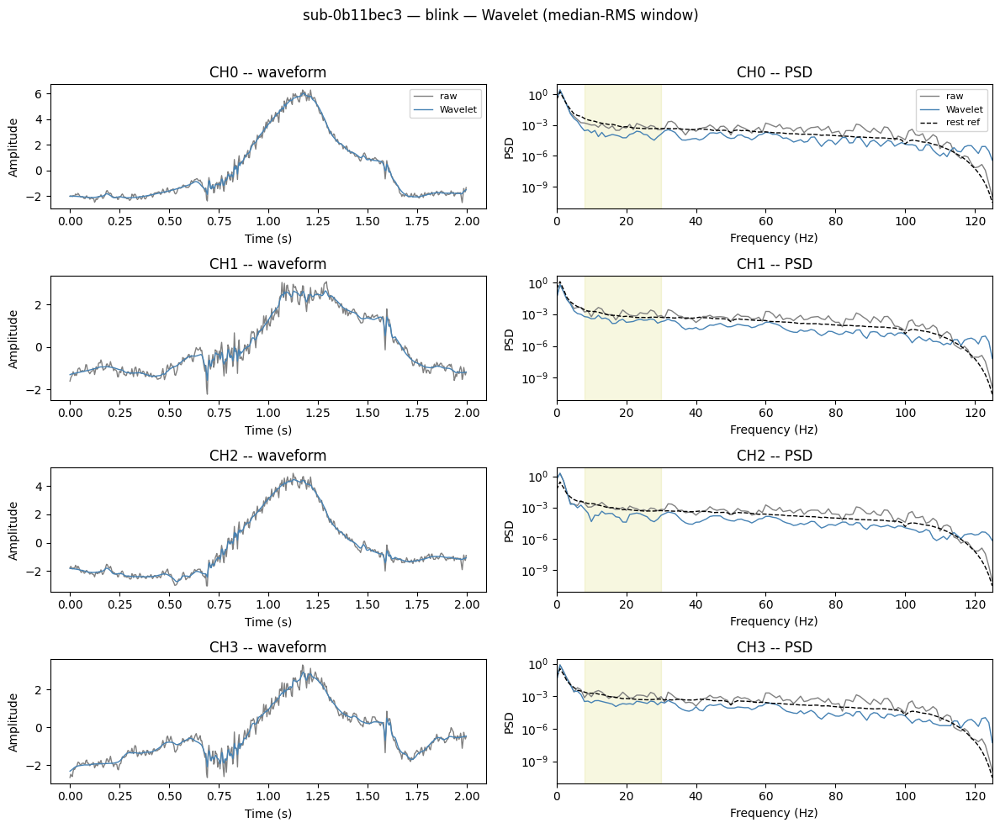

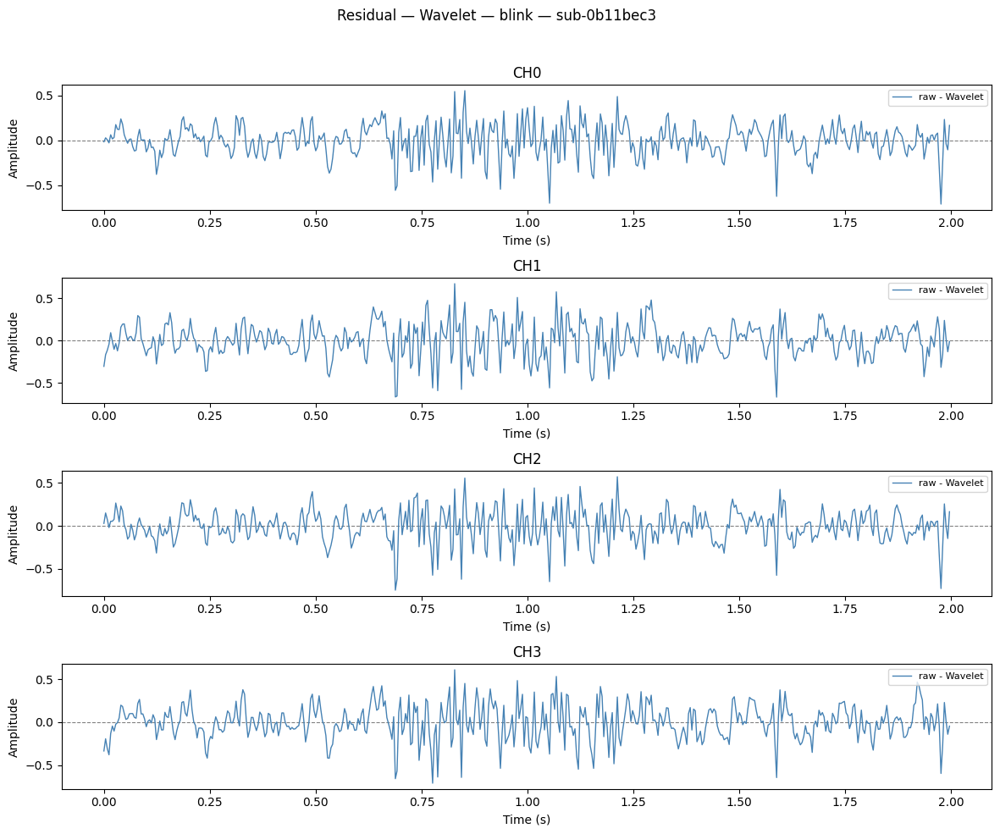

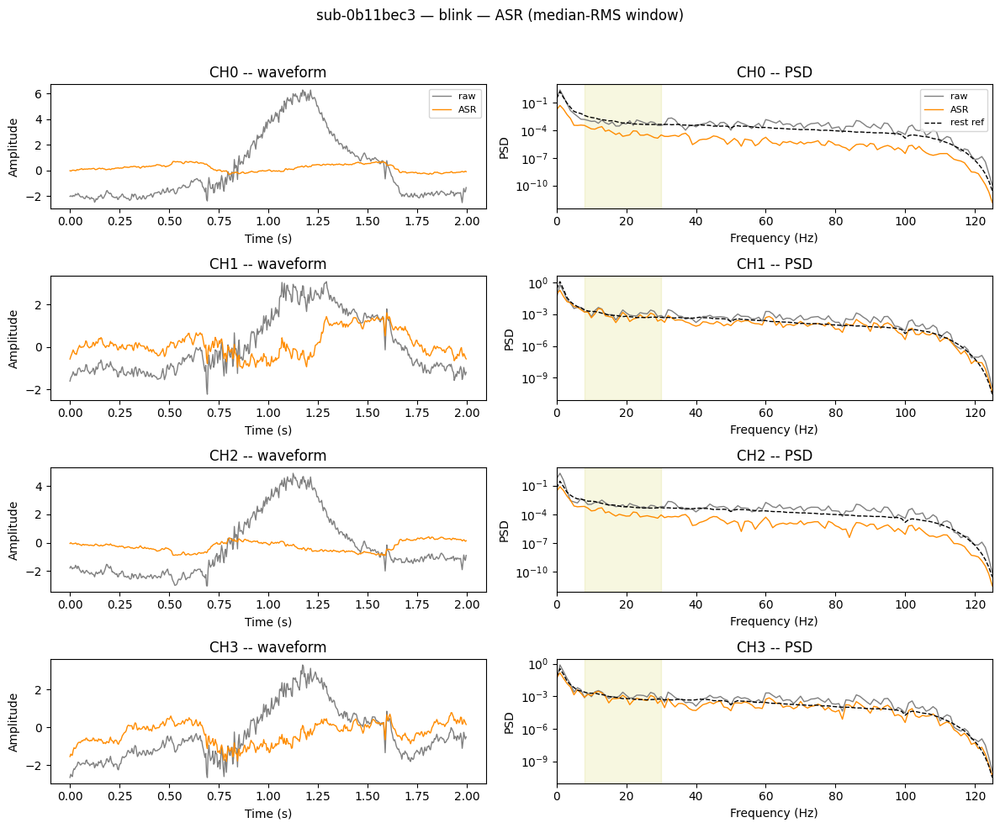

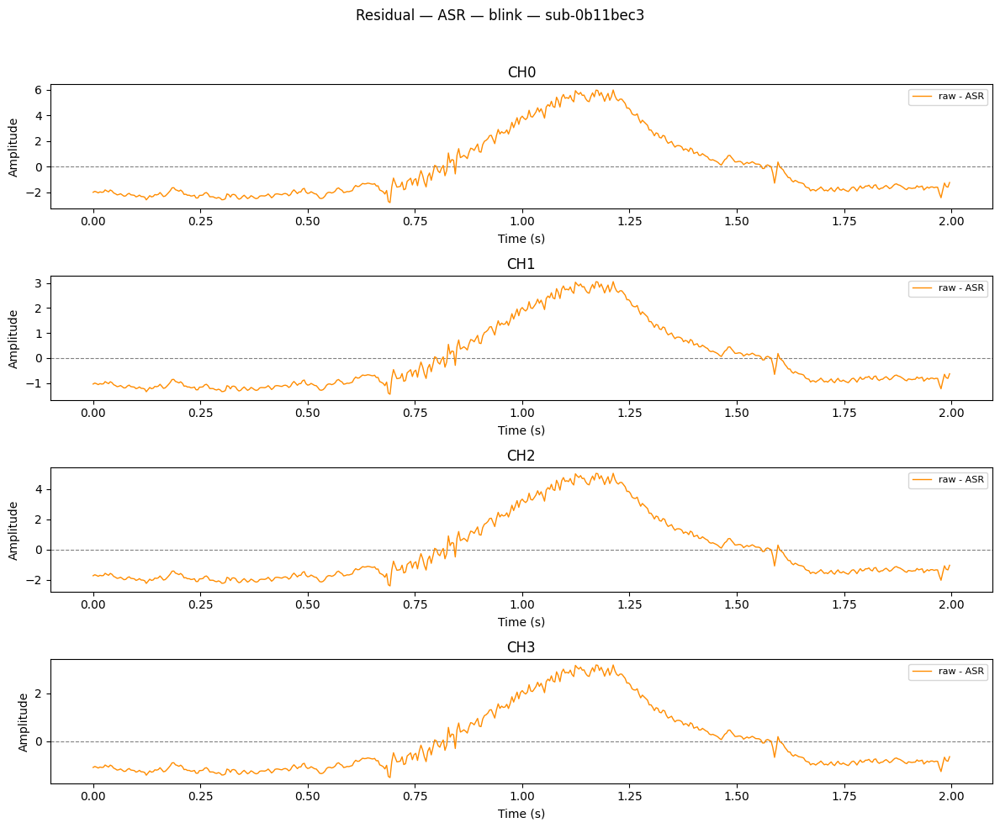

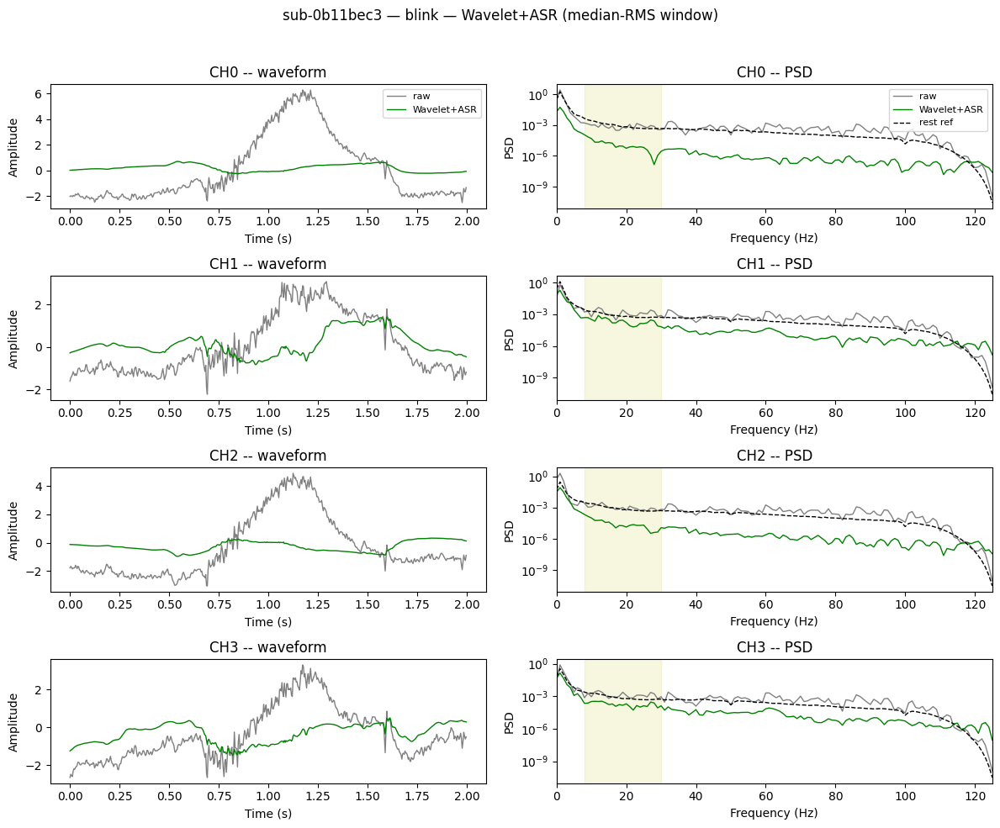

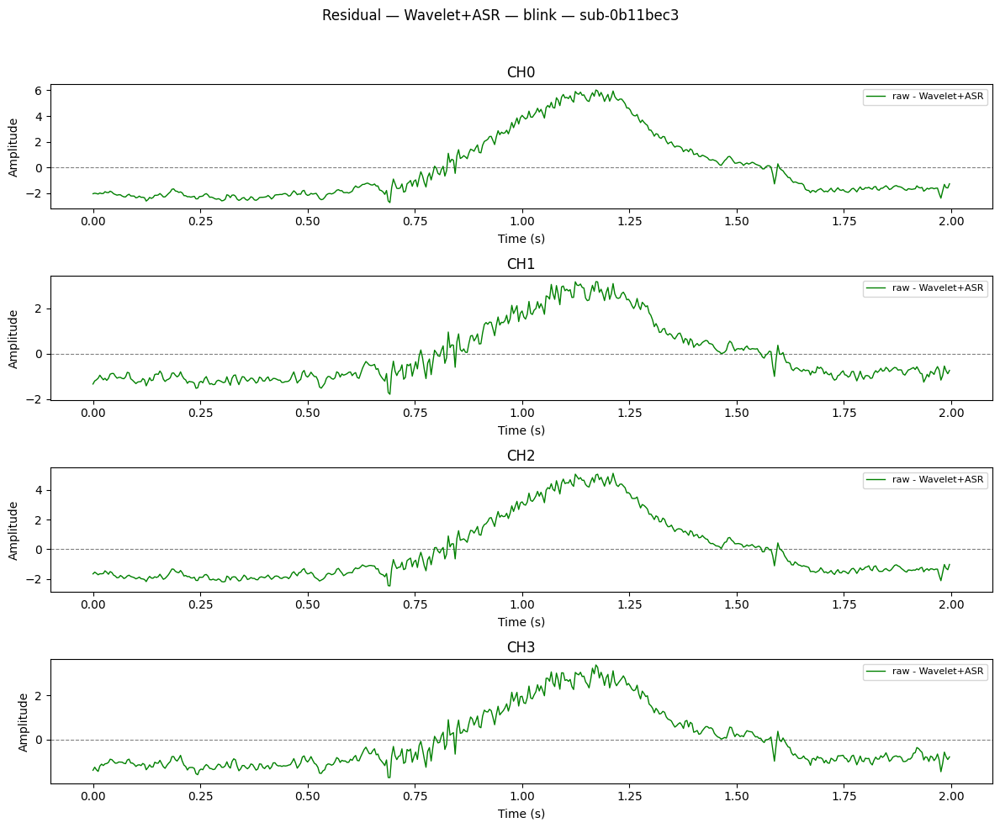

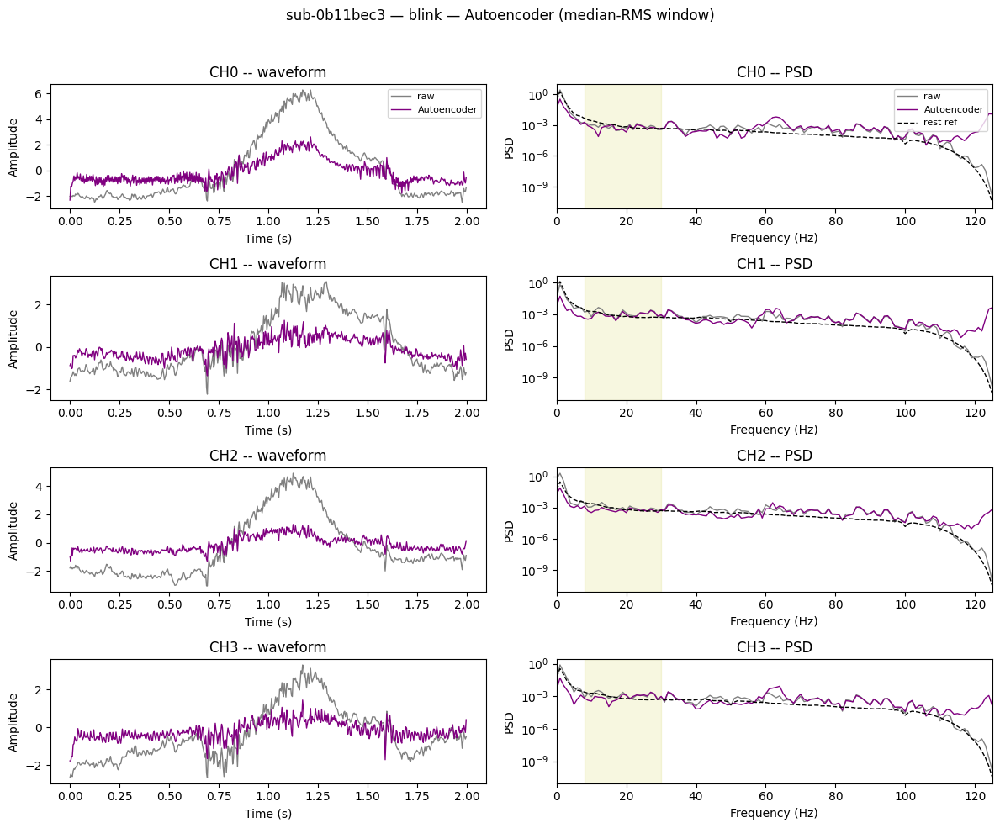

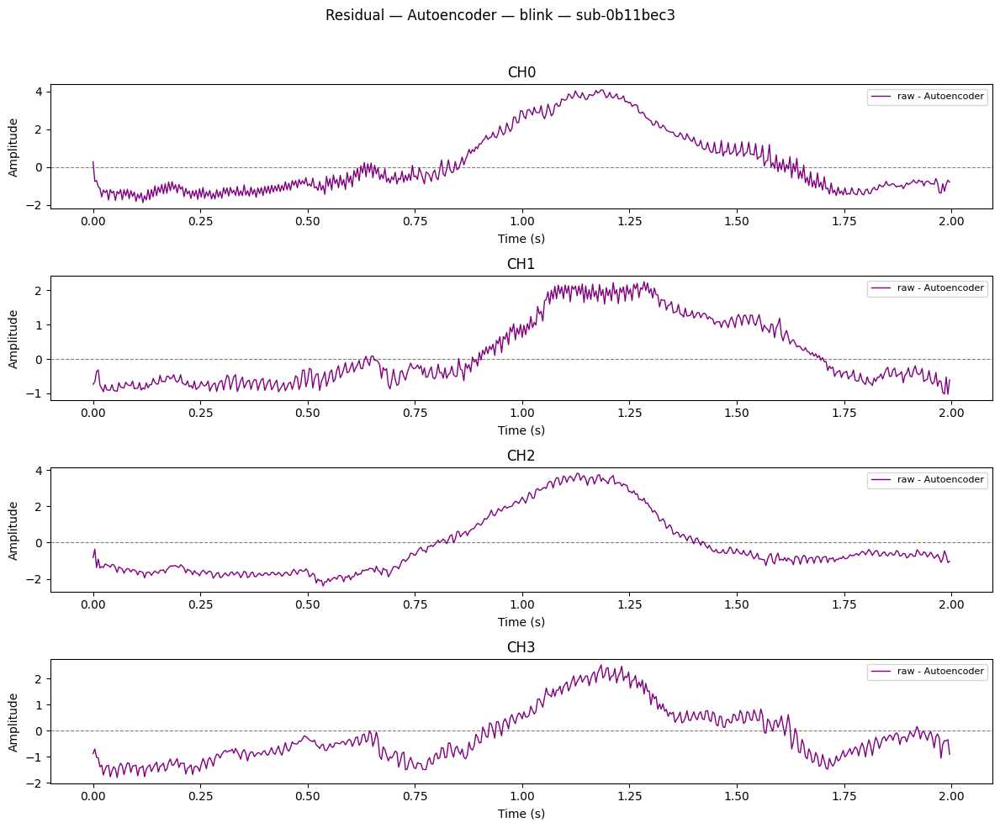

=== Pooled metrics (all subjects) -- blink ===


,Artifact-band attenuation (dB),SNR improvement (dB),RMS reduction (dB)
method,,,
Wavelet,0.31,0.12,0.55
ASR,4.20,1.73,4.81
Wavelet+ASR,4.72,1.84,5.70
Autoencoder,9.19,1.94,7.19


In [10]:
# Section 1 -- blink: per-method figures for the representative subject.
art = "blink"
subj = CONFIG["REPR_SUBJECTS"][0]
if art not in raw_class_windows.get(subj, {}):
    print(f"  ({subj}: no '{art}' windows -- skipped)")
else:
    for method in PLOT_METHODS:        # Wavelet -> ASR -> Wavelet+ASR -> Autoencoder
        plot_method_waveform_psd(subj, art, method)   # Figure A
        plot_method_residual(subj, art, method)       # Figure B

print(f"=== Pooled metrics (all subjects) -- {art} ===")
class_metrics_table(art)

## Section 2 — look_left

Per-method comparison for the **look_left** artifact (artifact band = 0.5–8 Hz). Figure A
(waveform + PSD) and Figure B (residuals) are shown for each representative
subject on its median-RMS window; the pooled metrics table aggregates across all
subjects.

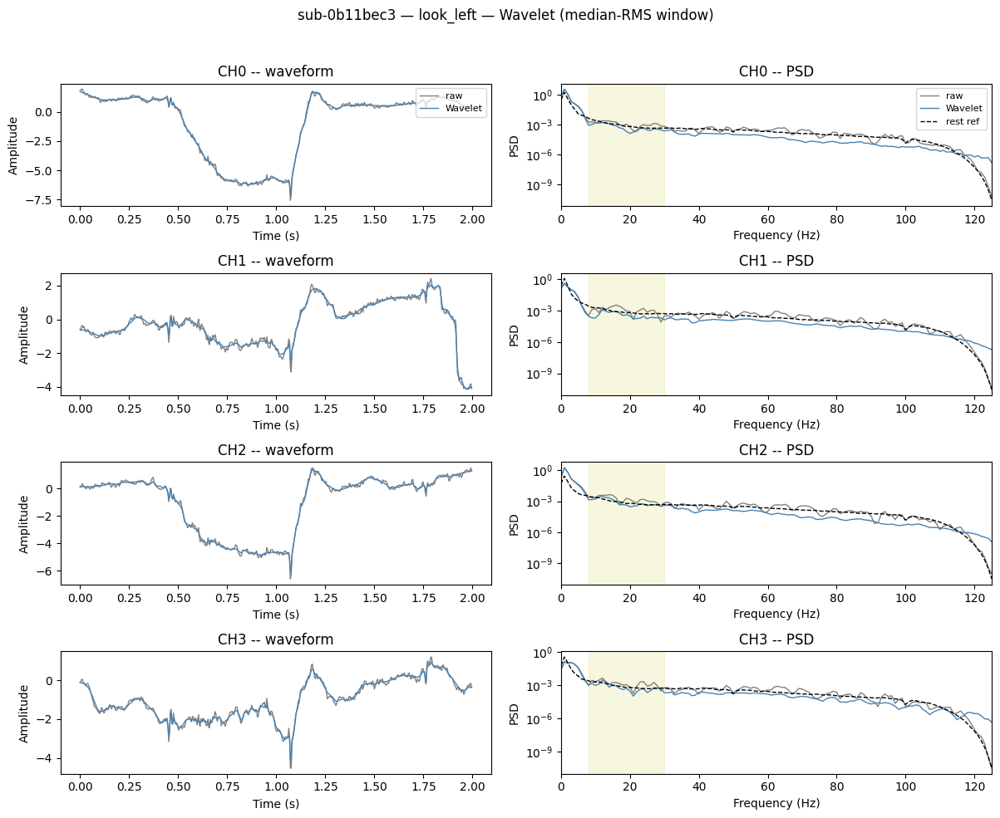

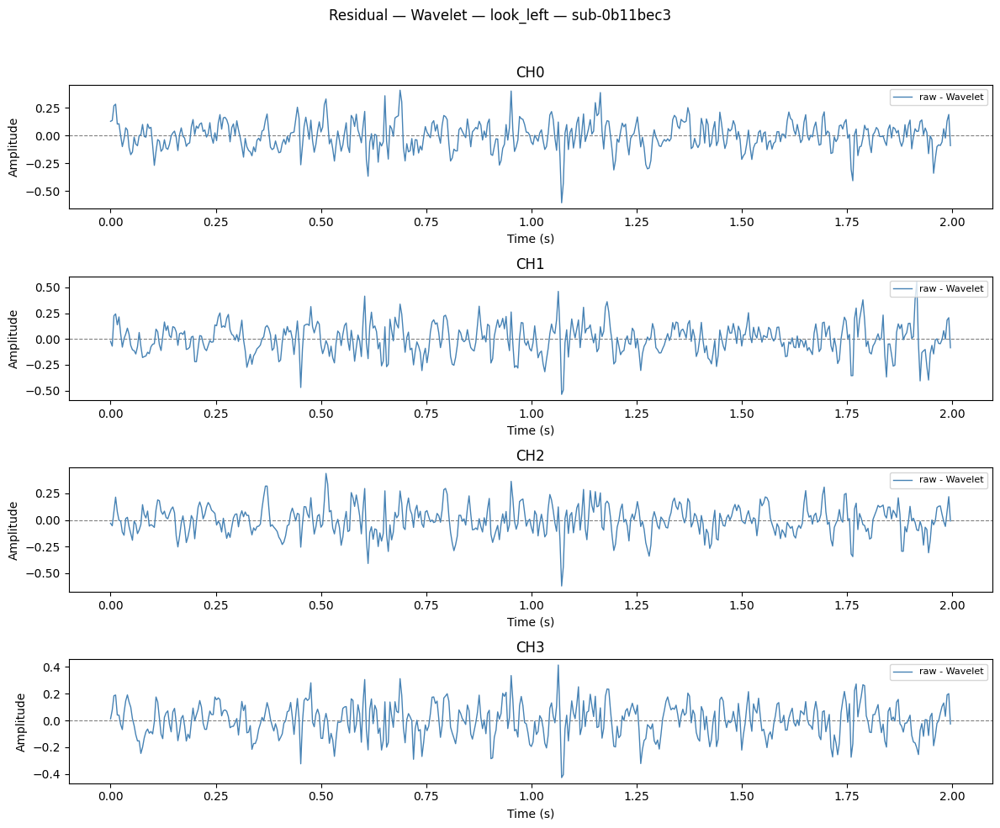

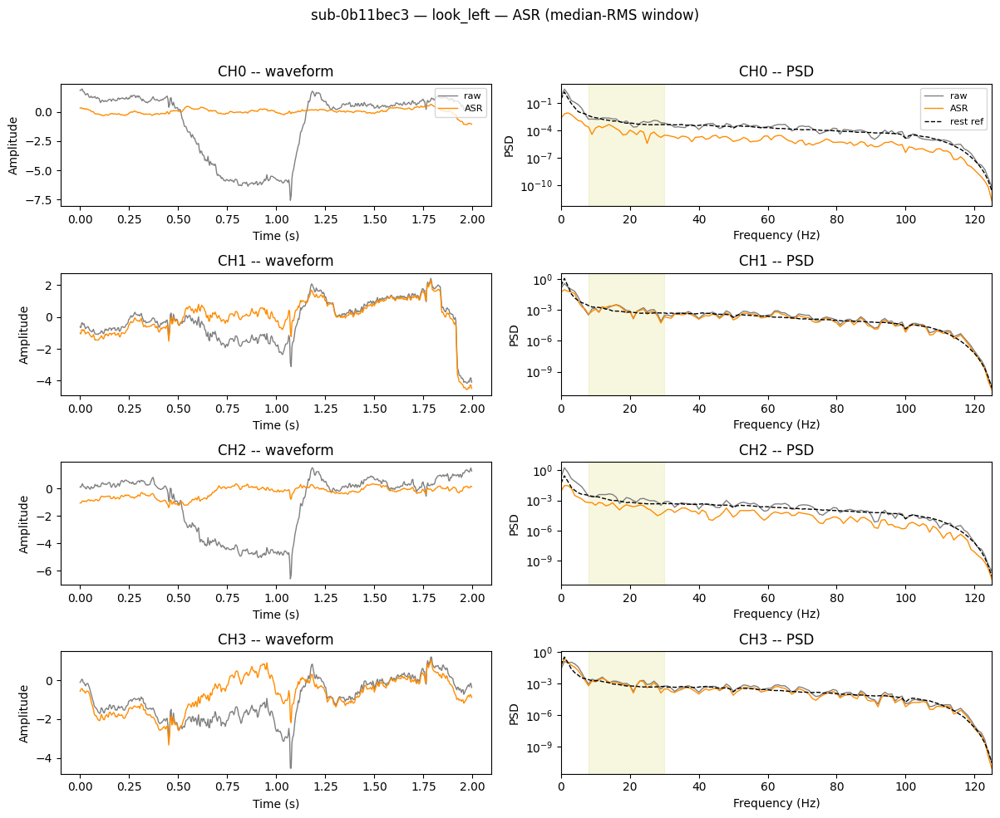

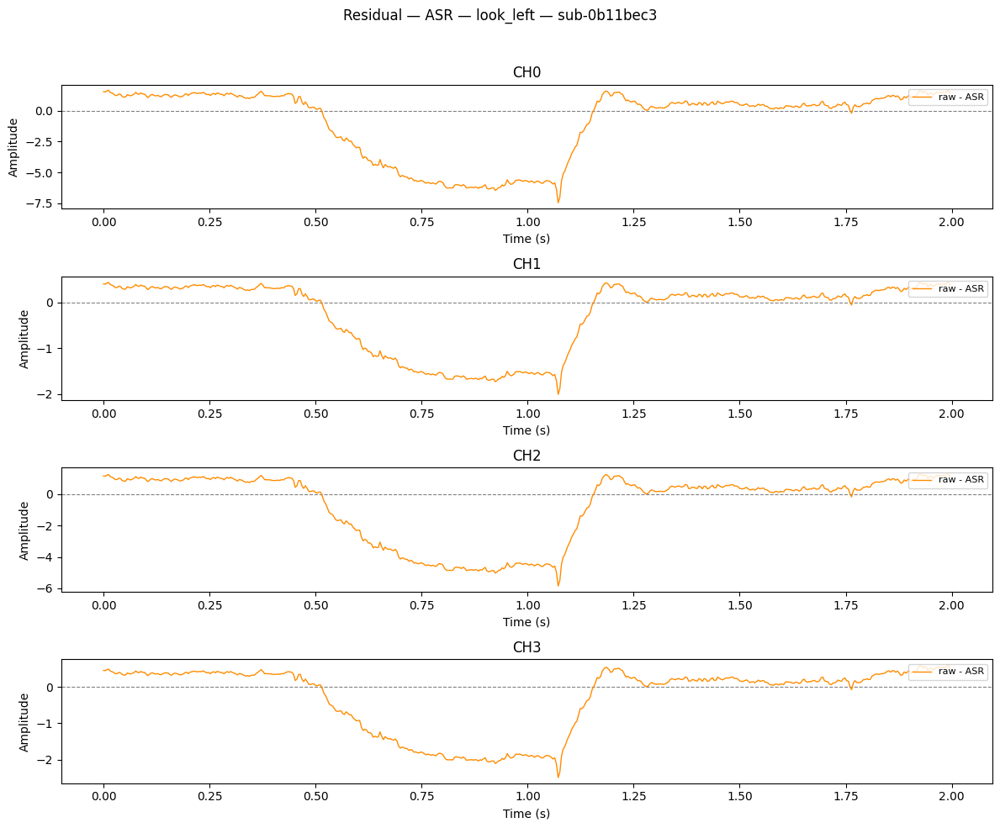

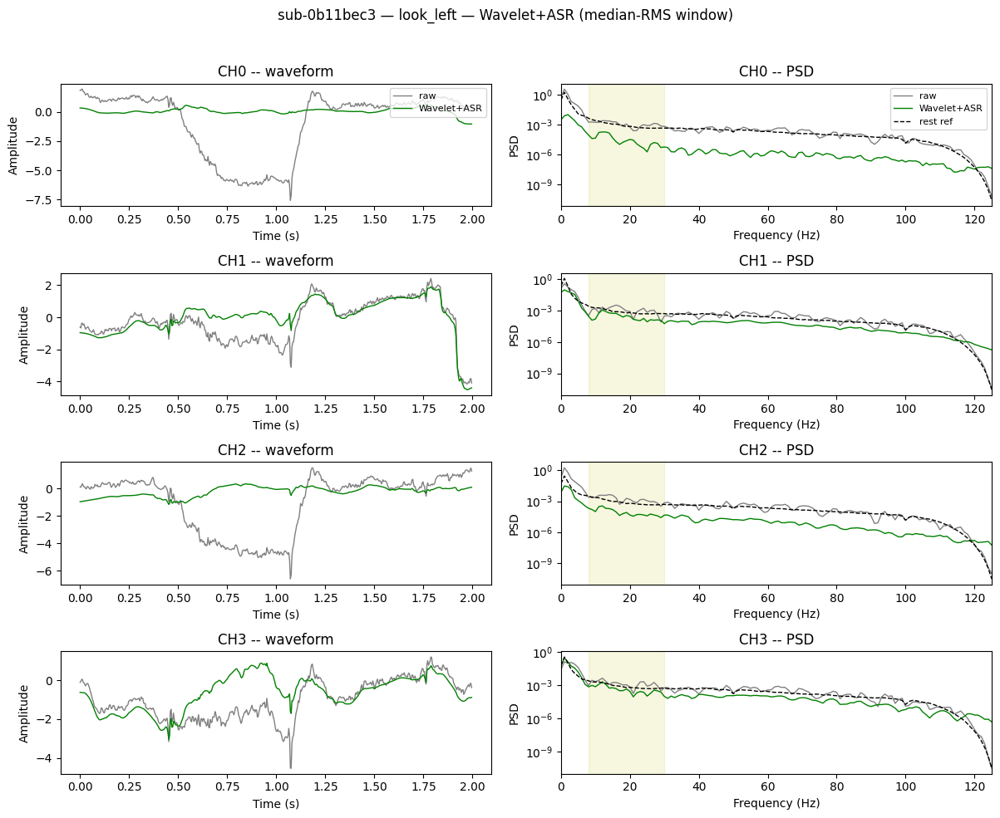

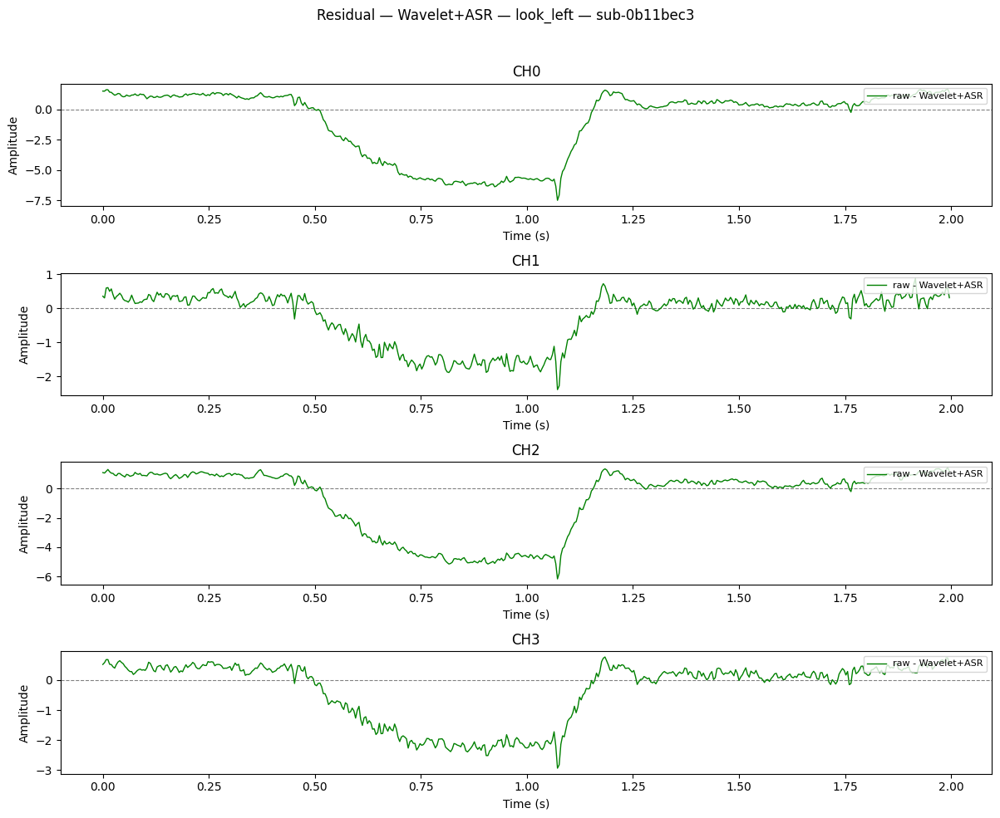

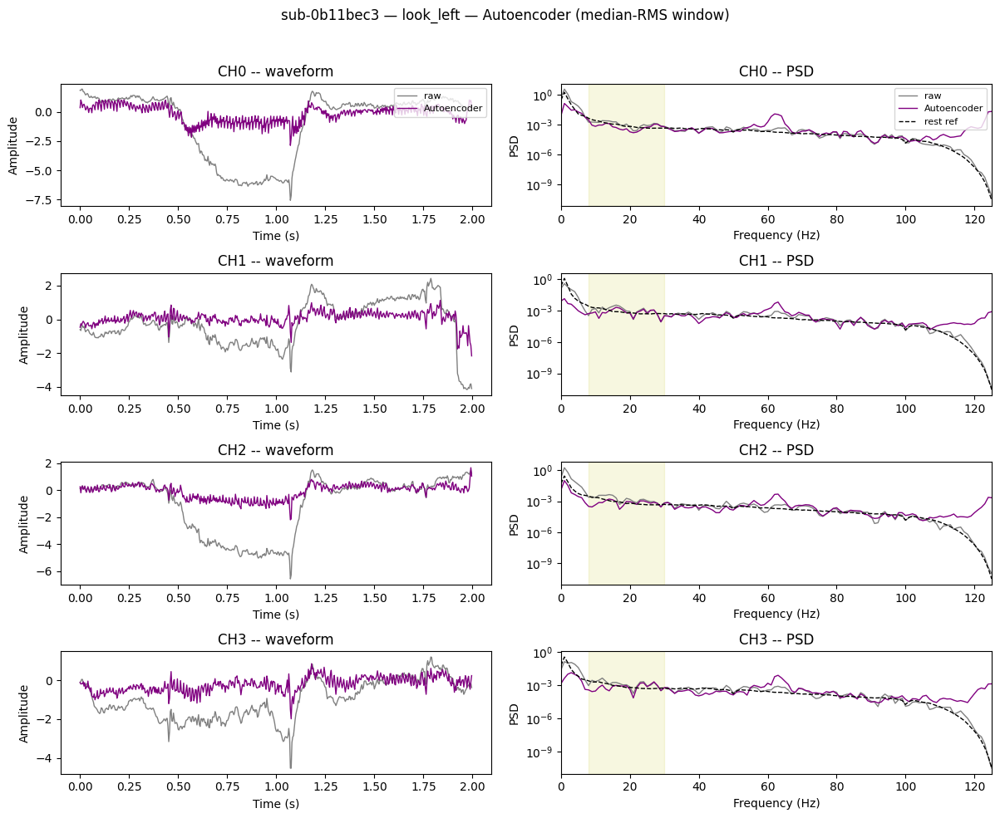

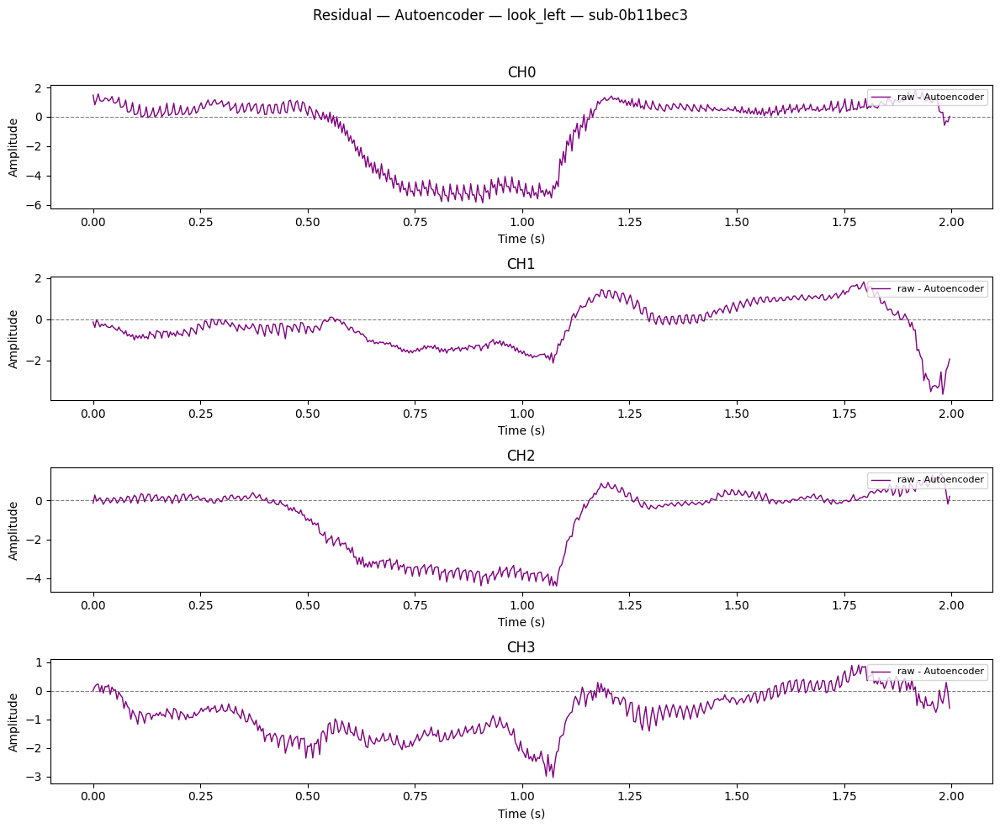

=== Pooled metrics (all subjects) -- look_left ===


,Artifact-band attenuation (dB),SNR improvement (dB),RMS reduction (dB)
method,,,
Wavelet,0.26,0.10,0.34
ASR,7.20,3.10,8.34
Wavelet+ASR,7.68,3.20,9.20
Autoencoder,10.92,3.31,9.28


In [11]:
# Section 2 -- look_left: per-method figures for the representative subject.
art = "look_left"
subj = CONFIG["REPR_SUBJECTS"][0]
if art not in raw_class_windows.get(subj, {}):
    print(f"  ({subj}: no '{art}' windows -- skipped)")
else:
    for method in PLOT_METHODS:        # Wavelet -> ASR -> Wavelet+ASR -> Autoencoder
        plot_method_waveform_psd(subj, art, method)   # Figure A
        plot_method_residual(subj, art, method)       # Figure B

print(f"=== Pooled metrics (all subjects) -- {art} ===")
class_metrics_table(art)

## Section 3 — look_right

Per-method comparison for the **look_right** artifact (artifact band = 0.5–8 Hz). Figure A
(waveform + PSD) and Figure B (residuals) are shown for each representative
subject on its median-RMS window; the pooled metrics table aggregates across all
subjects.

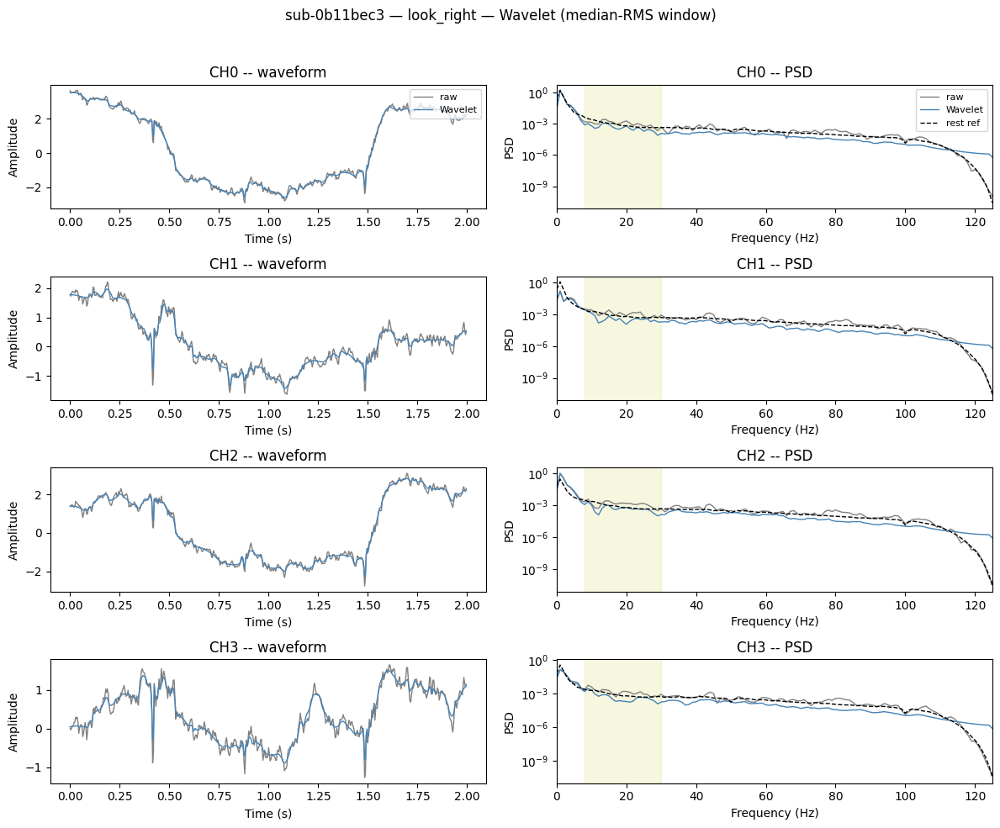

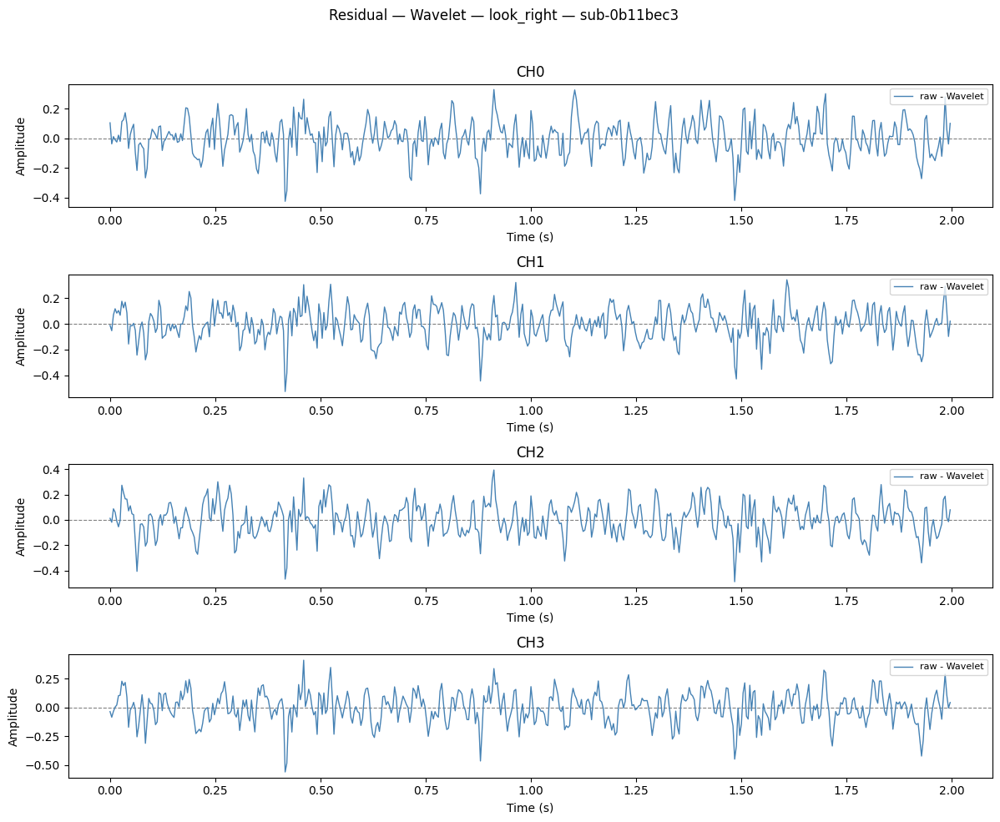

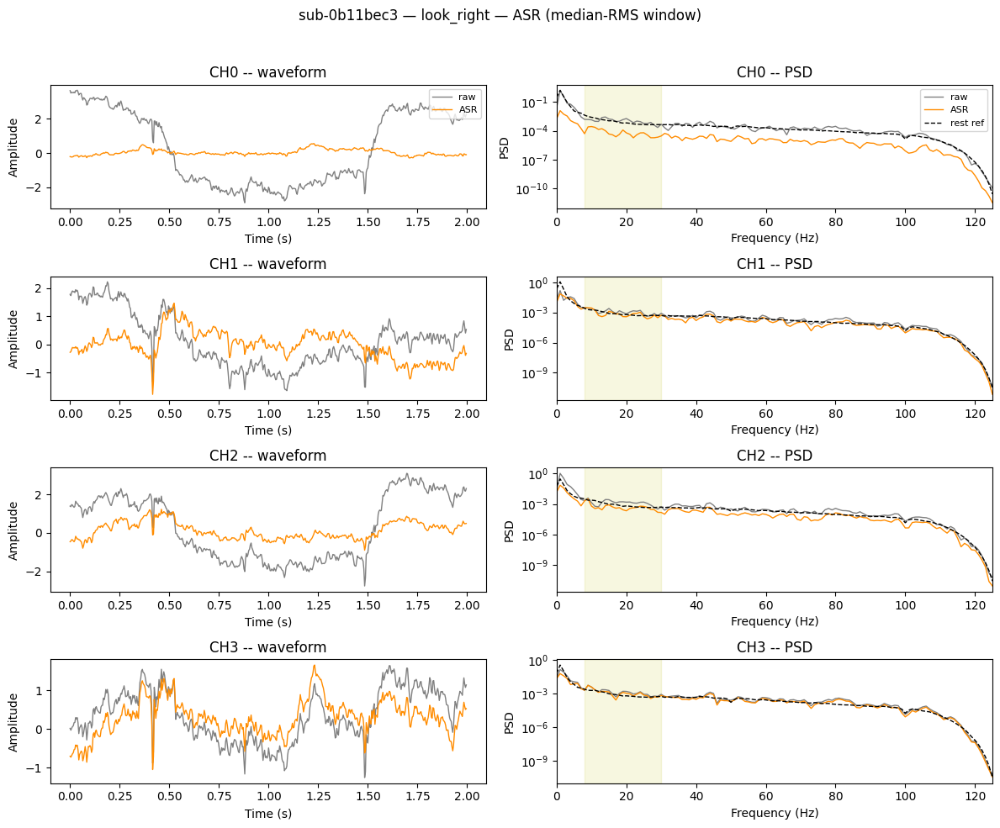

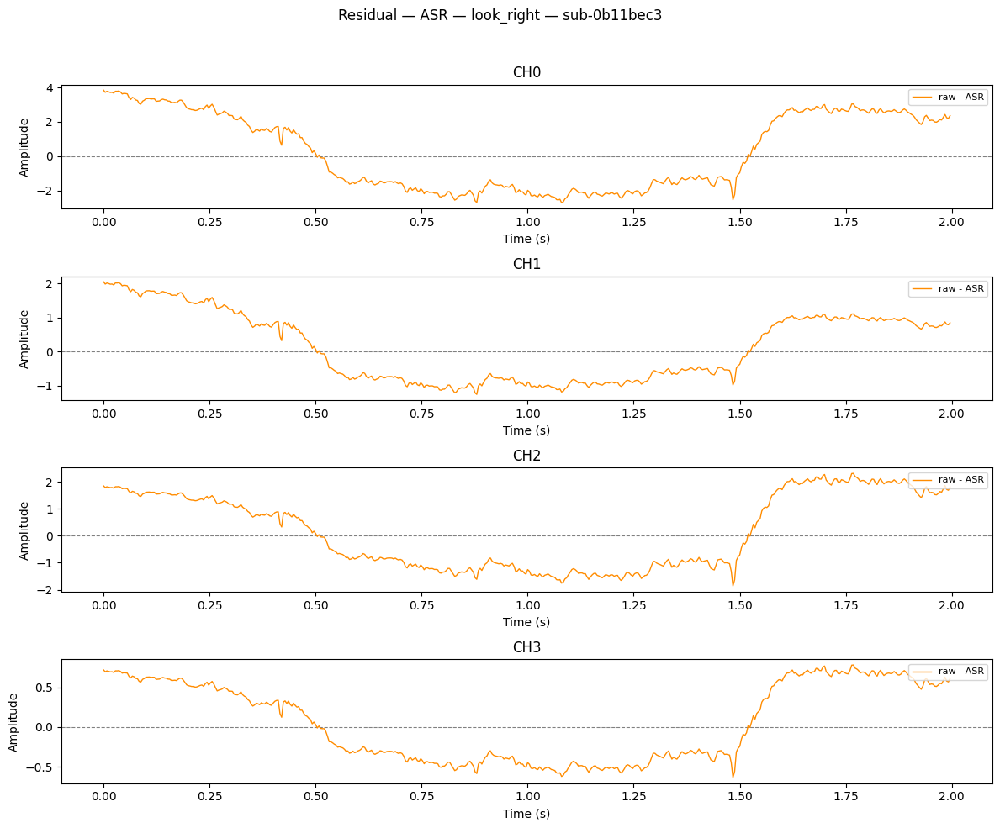

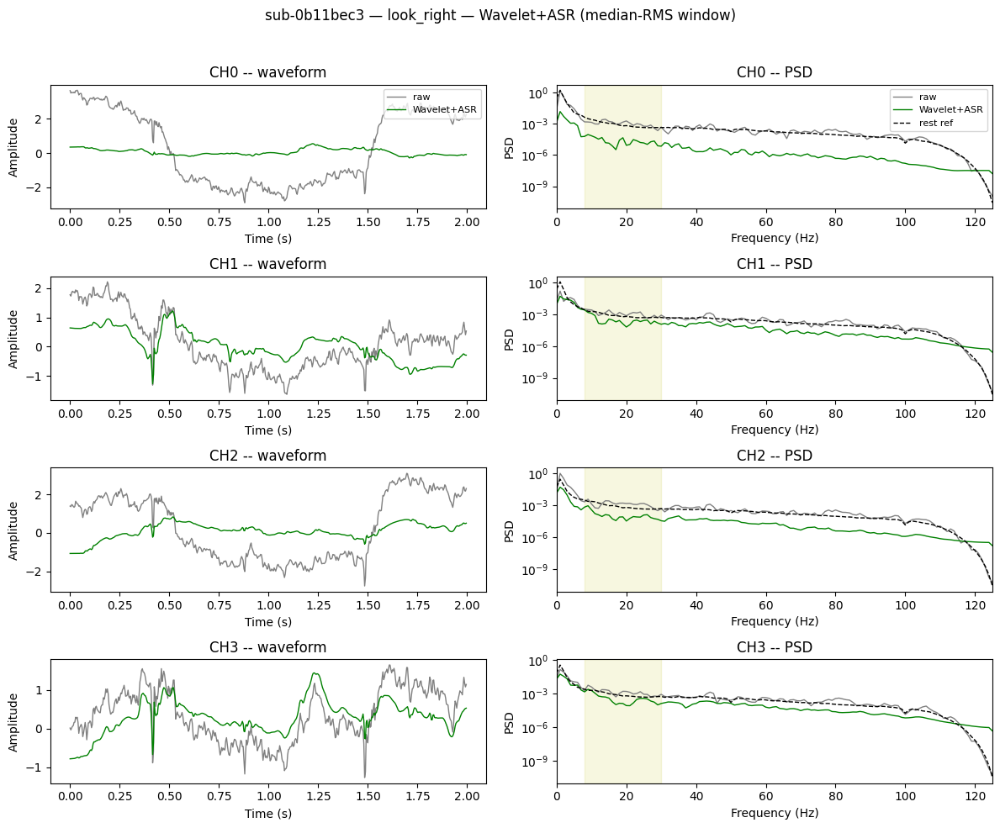

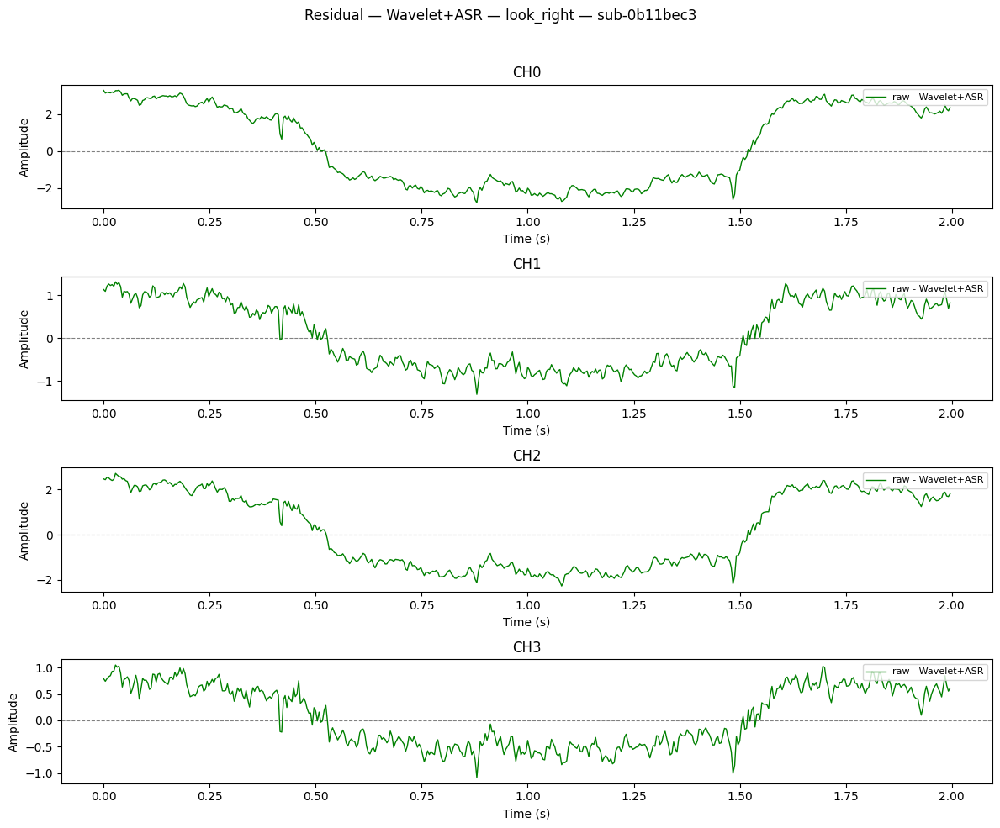

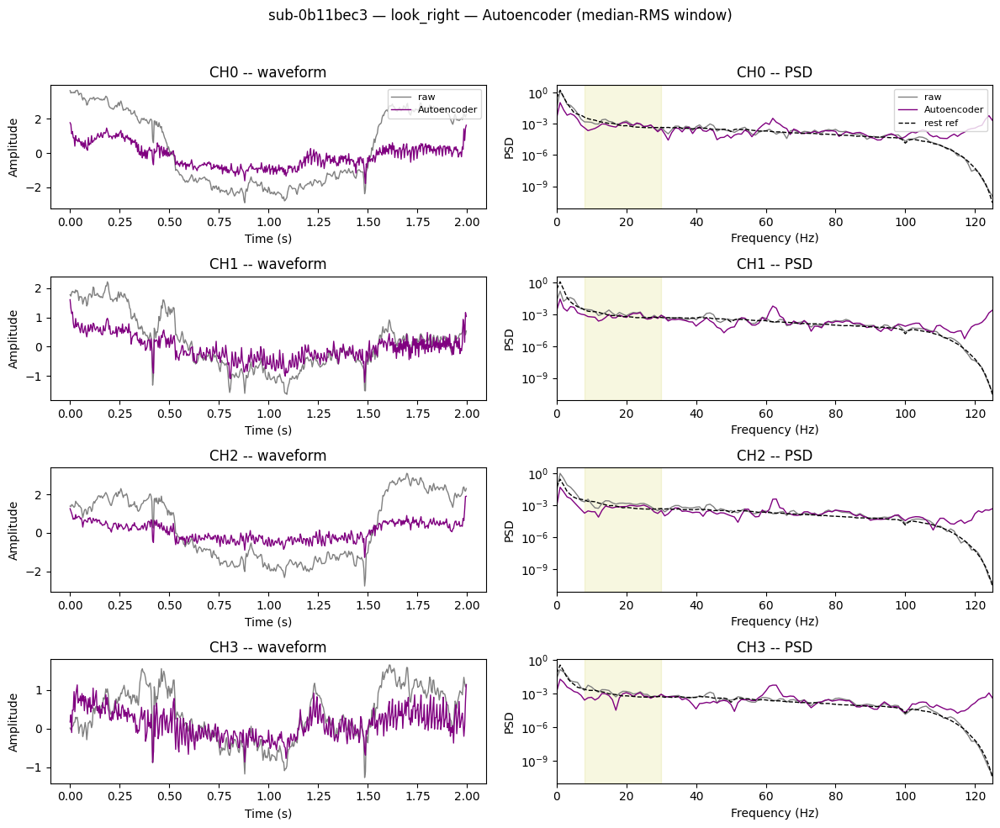

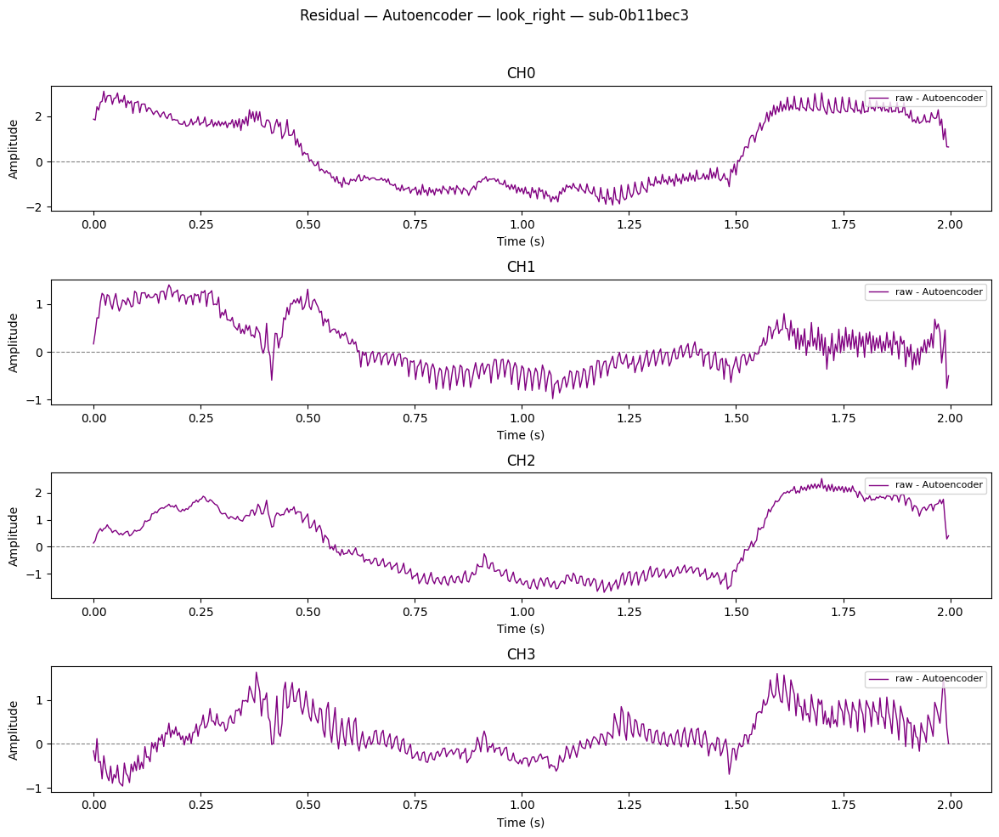

=== Pooled metrics (all subjects) -- look_right ===


,Artifact-band attenuation (dB),SNR improvement (dB),RMS reduction (dB)
method,,,
Wavelet,0.28,0.12,0.35
ASR,4.91,2.15,6.63
Wavelet+ASR,5.42,2.30,7.50
Autoencoder,10.45,2.12,8.52


In [12]:
# Section 3 -- look_right: per-method figures for the representative subject.
art = "look_right"
subj = CONFIG["REPR_SUBJECTS"][0]
if art not in raw_class_windows.get(subj, {}):
    print(f"  ({subj}: no '{art}' windows -- skipped)")
else:
    for method in PLOT_METHODS:        # Wavelet -> ASR -> Wavelet+ASR -> Autoencoder
        plot_method_waveform_psd(subj, art, method)   # Figure A
        plot_method_residual(subj, art, method)       # Figure B

print(f"=== Pooled metrics (all subjects) -- {art} ===")
class_metrics_table(art)

## Section 4 — horiz_head

Per-method comparison for the **horiz_head** artifact (artifact band = 0.5–8 Hz). Figure A
(waveform + PSD) and Figure B (residuals) are shown for each representative
subject on its median-RMS window; the pooled metrics table aggregates across all
subjects.

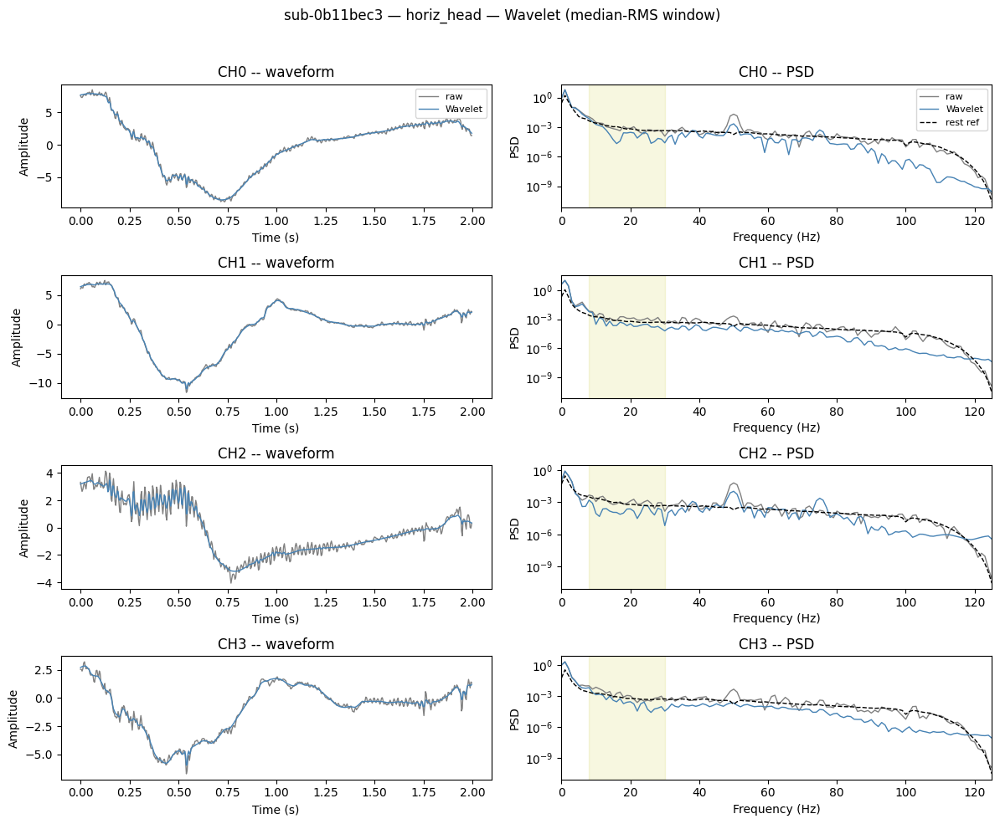

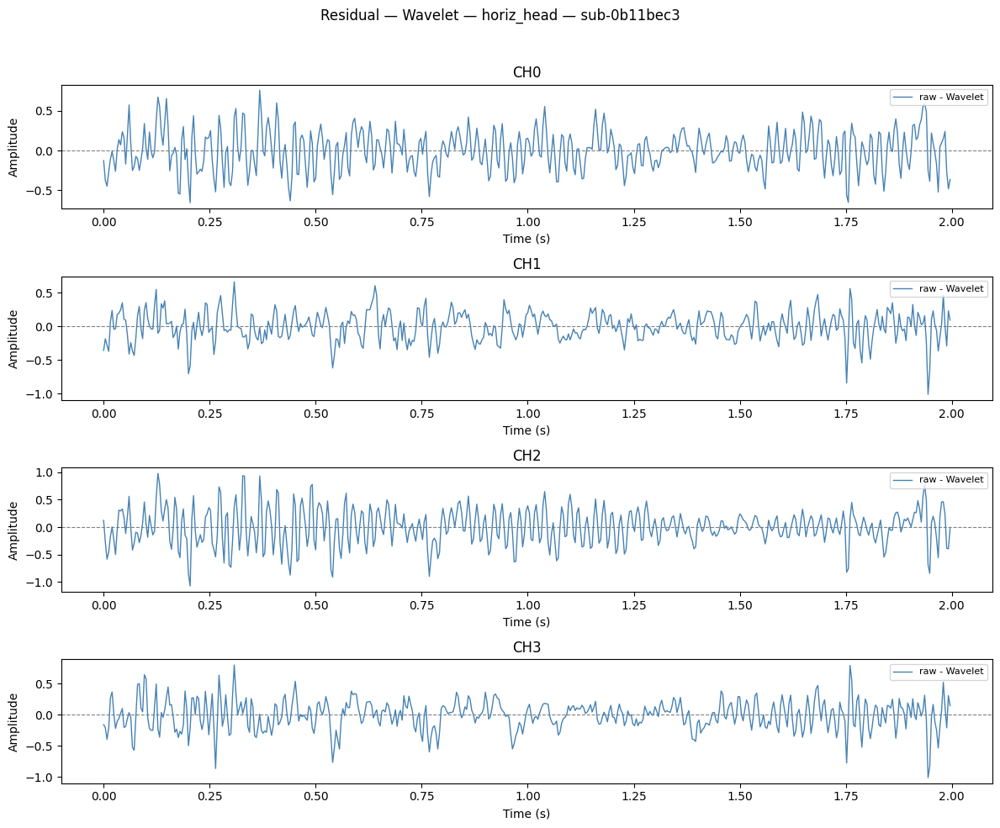

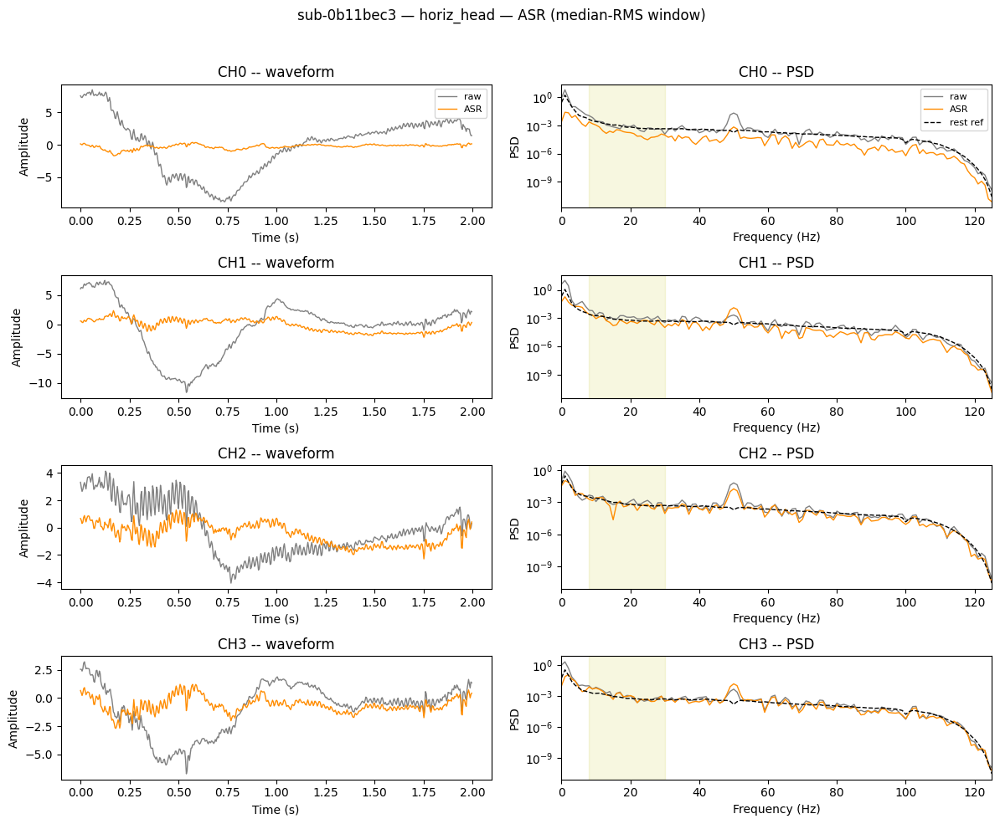

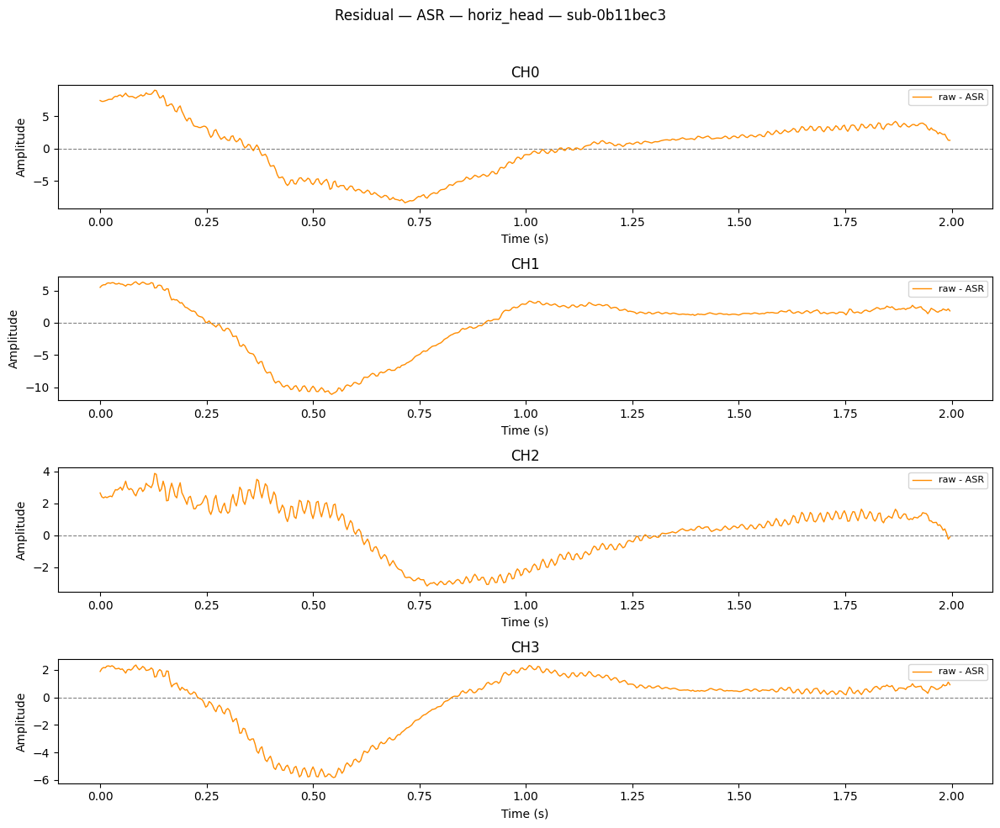

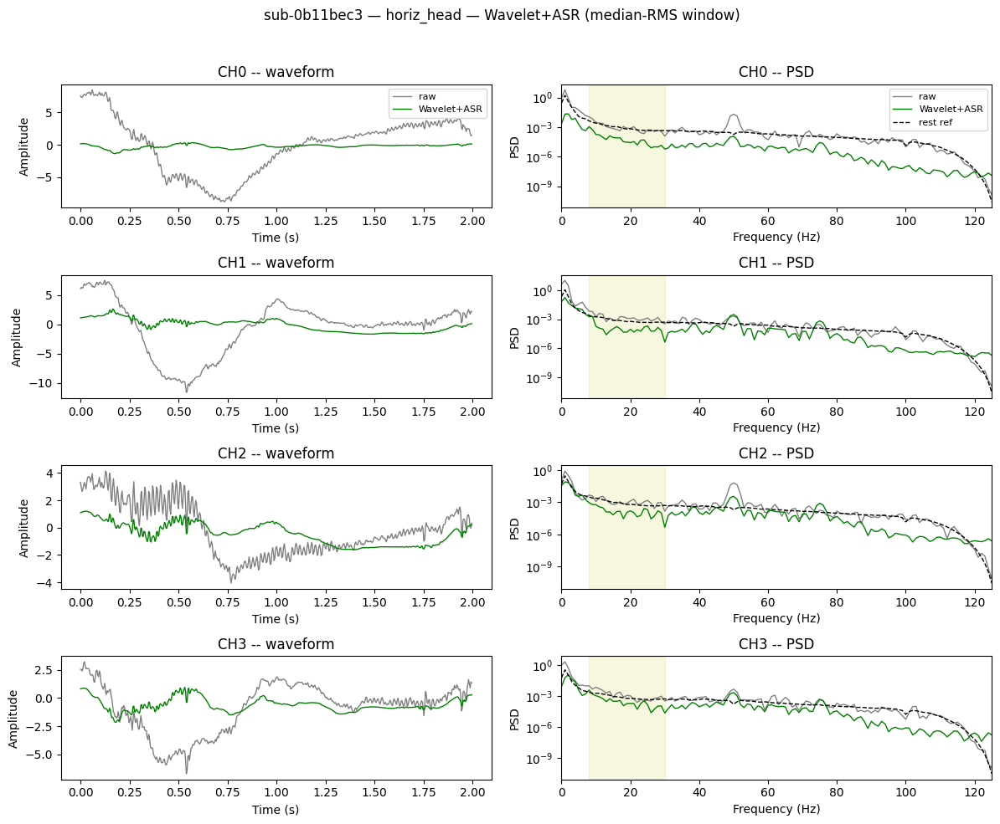

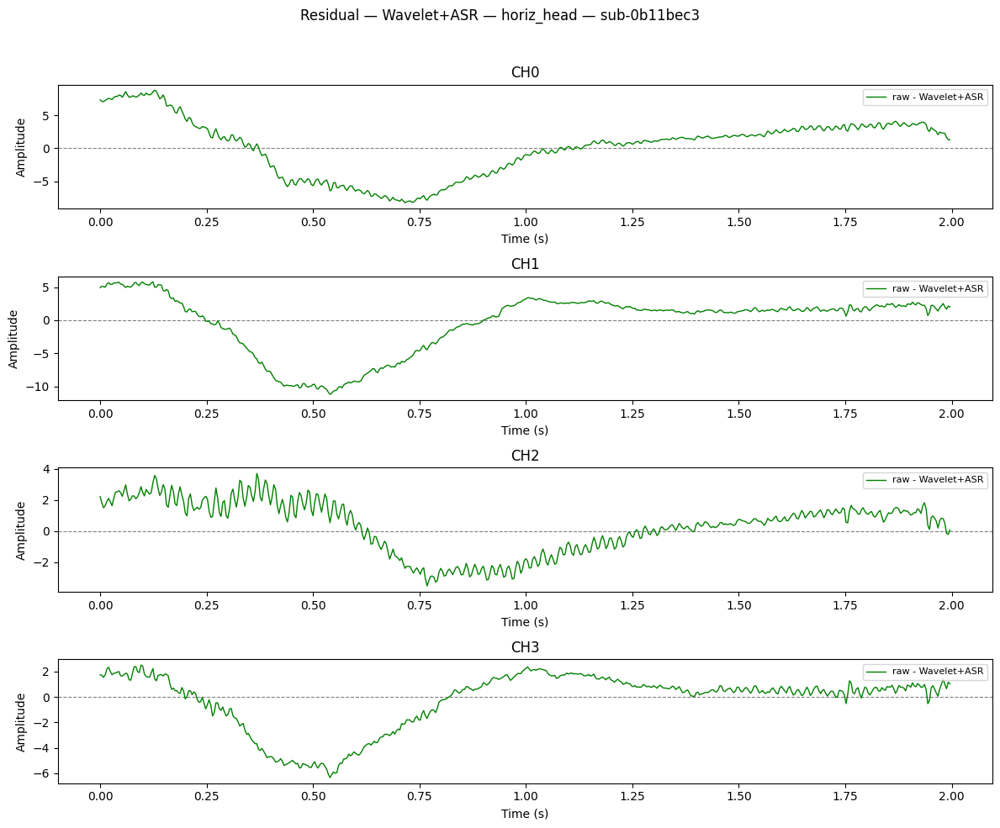

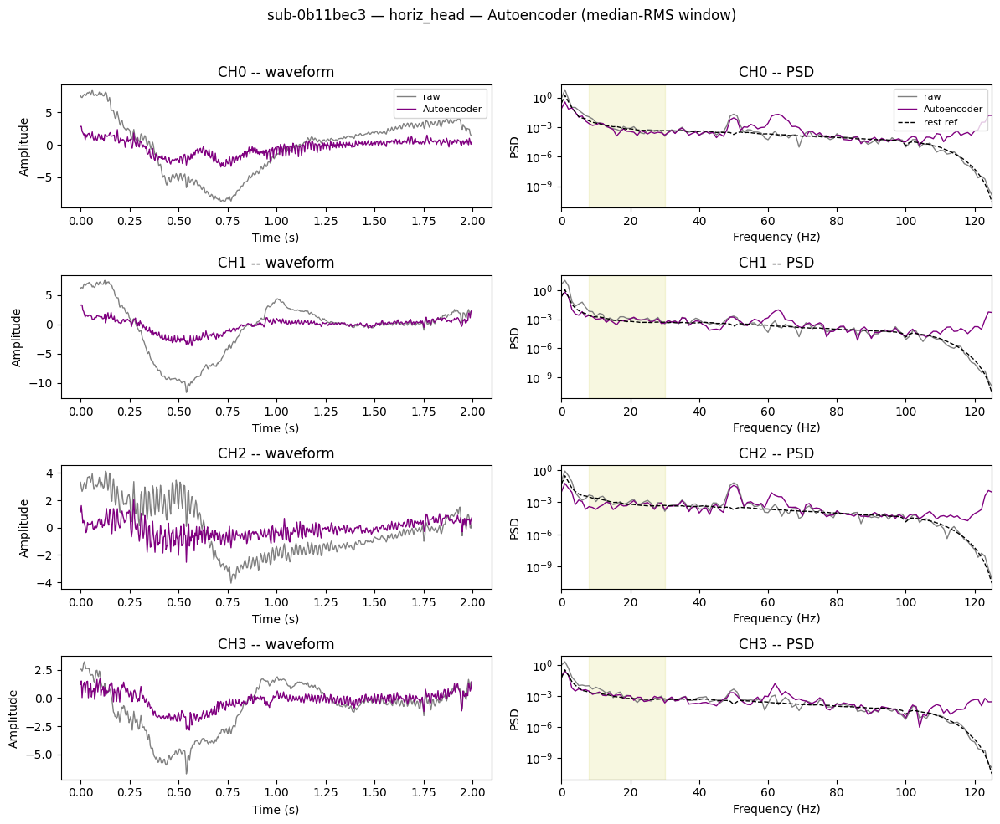

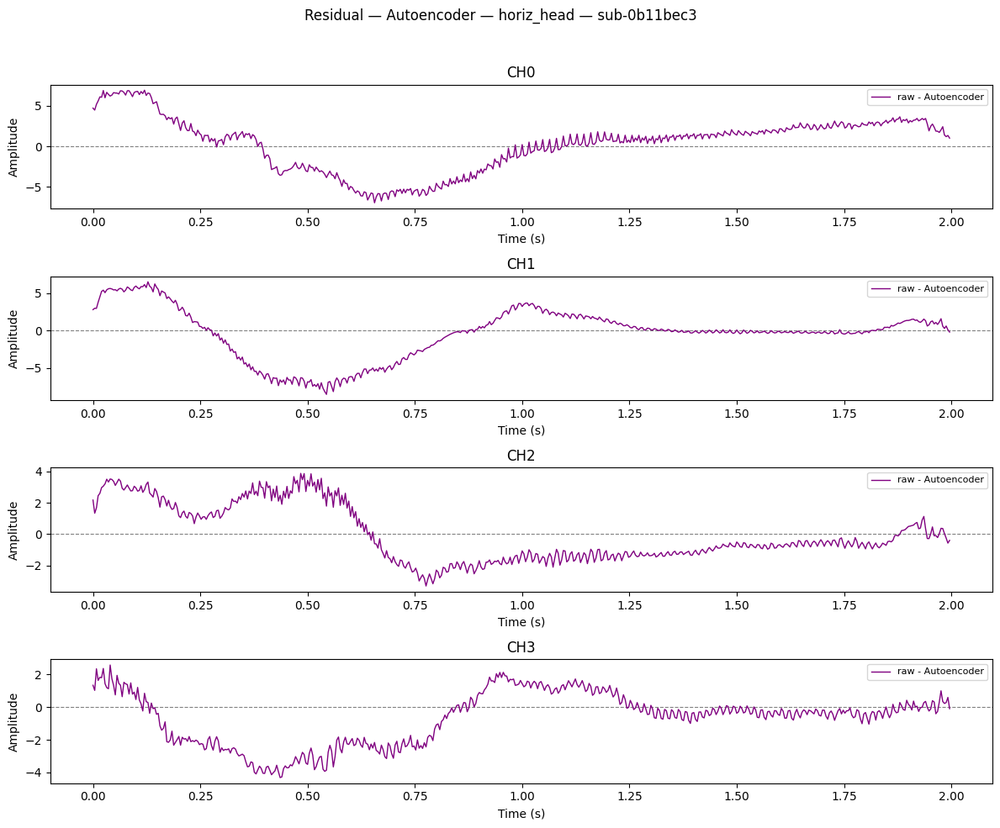

=== Pooled metrics (all subjects) -- horiz_head ===


,Artifact-band attenuation (dB),SNR improvement (dB),RMS reduction (dB)
method,,,
Wavelet,0.20,0.49,0.72
ASR,9.93,5.94,10.05
Wavelet+ASR,10.40,6.35,11.37
Autoencoder,11.87,5.49,9.62


In [13]:
# Section 4 -- horiz_head: per-method figures for the representative subject.
art = "horiz_head"
subj = CONFIG["REPR_SUBJECTS"][0]
if art not in raw_class_windows.get(subj, {}):
    print(f"  ({subj}: no '{art}' windows -- skipped)")
else:
    for method in PLOT_METHODS:        # Wavelet -> ASR -> Wavelet+ASR -> Autoencoder
        plot_method_waveform_psd(subj, art, method)   # Figure A
        plot_method_residual(subj, art, method)       # Figure B

print(f"=== Pooled metrics (all subjects) -- {art} ===")
class_metrics_table(art)

## Section 5 — vert_head

Per-method comparison for the **vert_head** artifact (artifact band = 0.5–8 Hz). Figure A
(waveform + PSD) and Figure B (residuals) are shown for each representative
subject on its median-RMS window; the pooled metrics table aggregates across all
subjects.

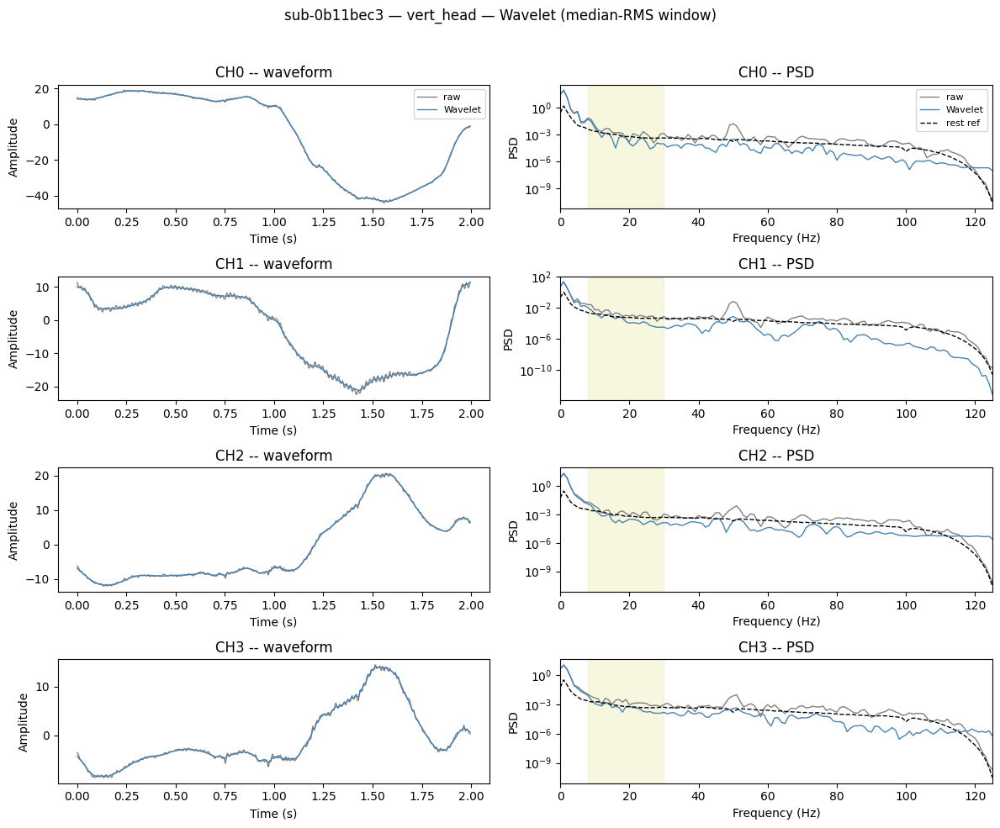

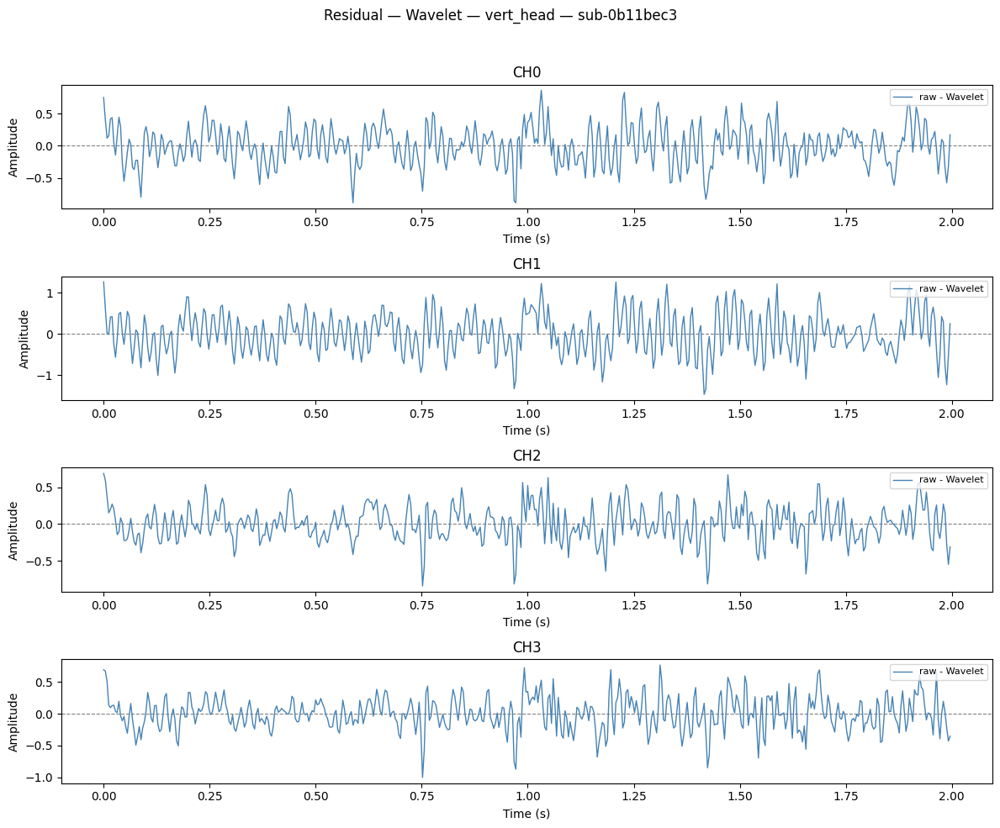

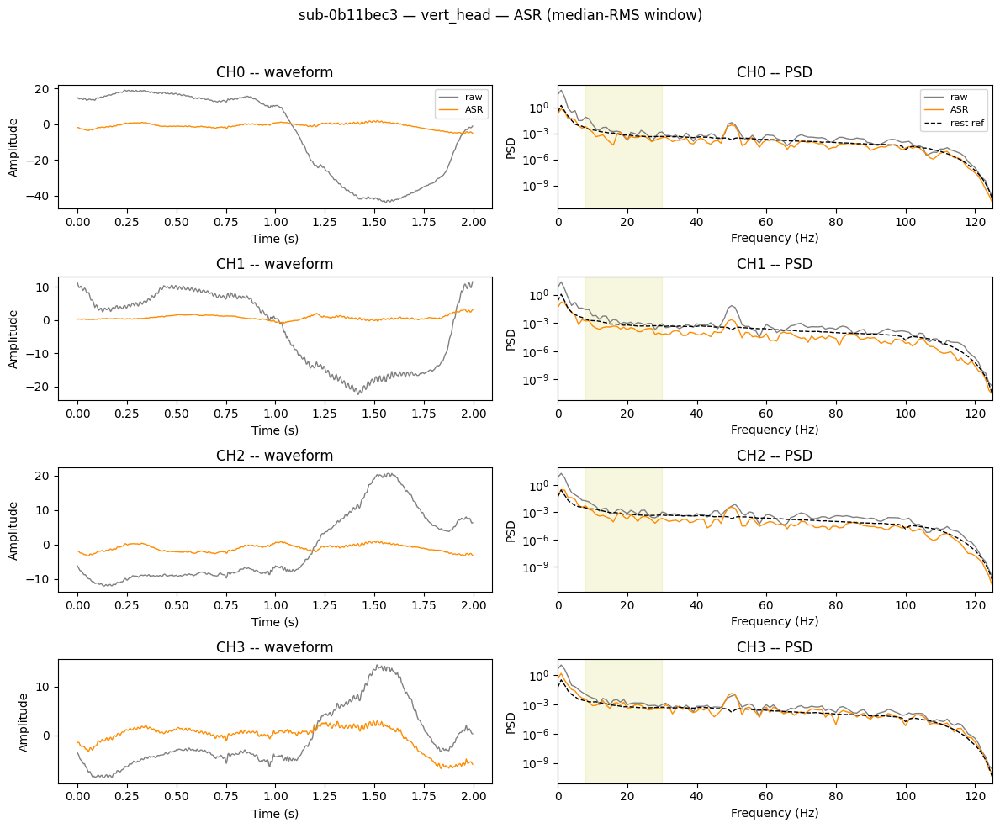

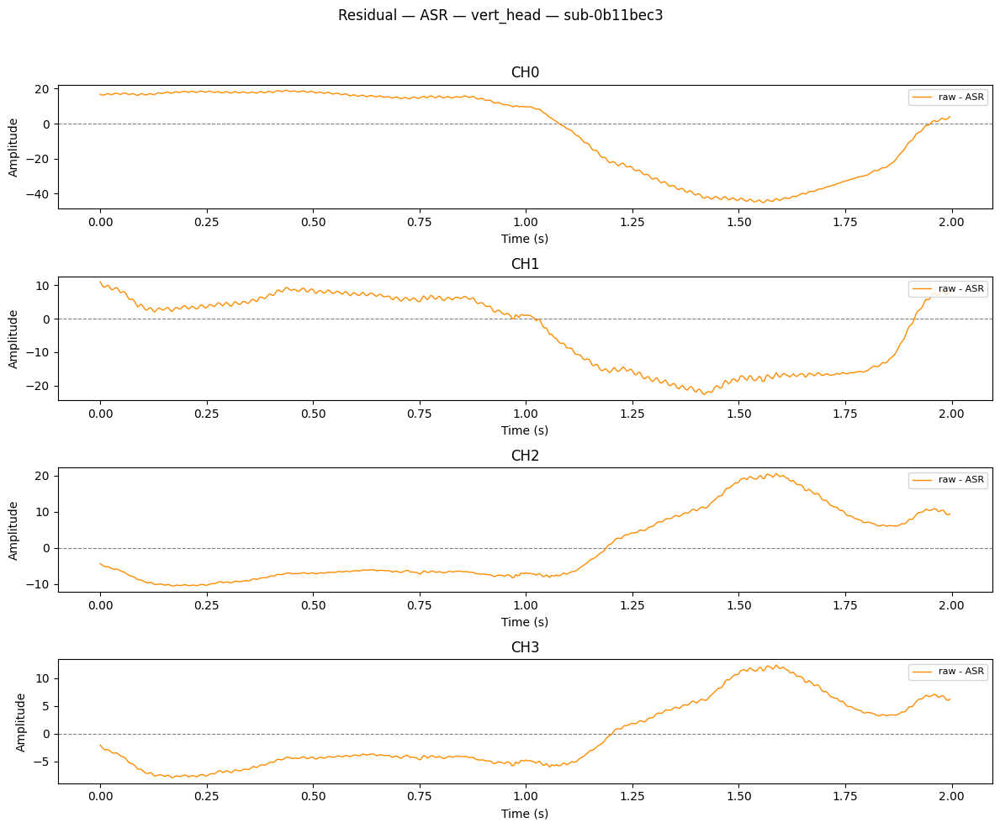

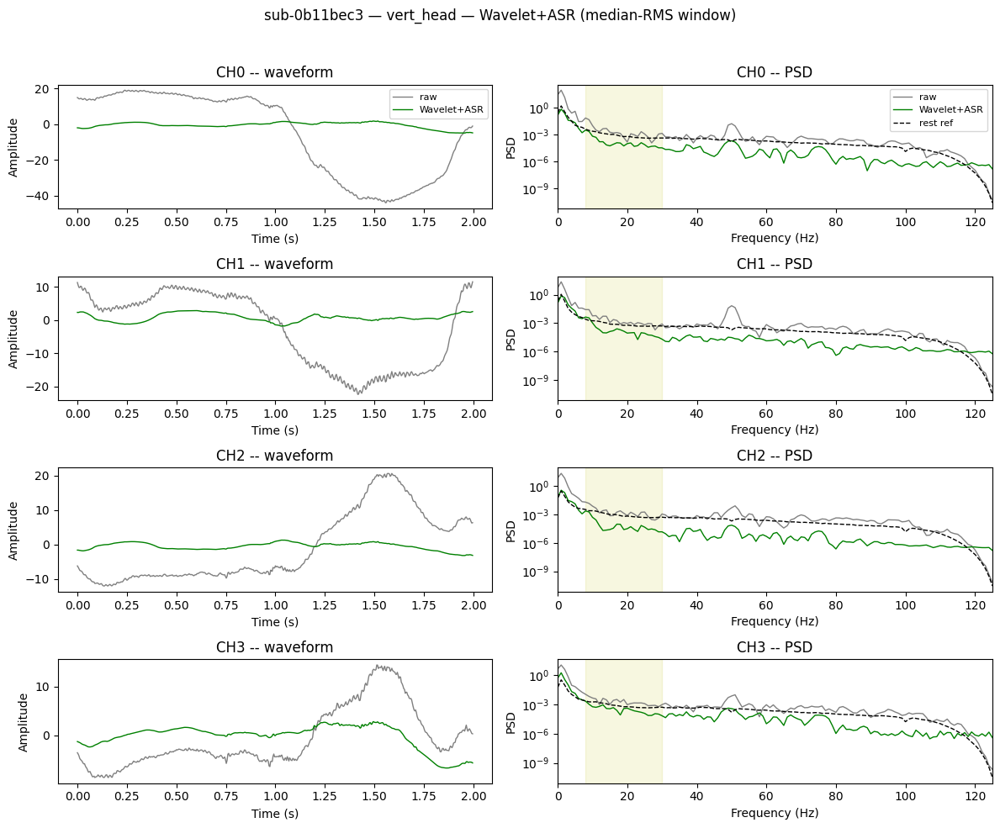

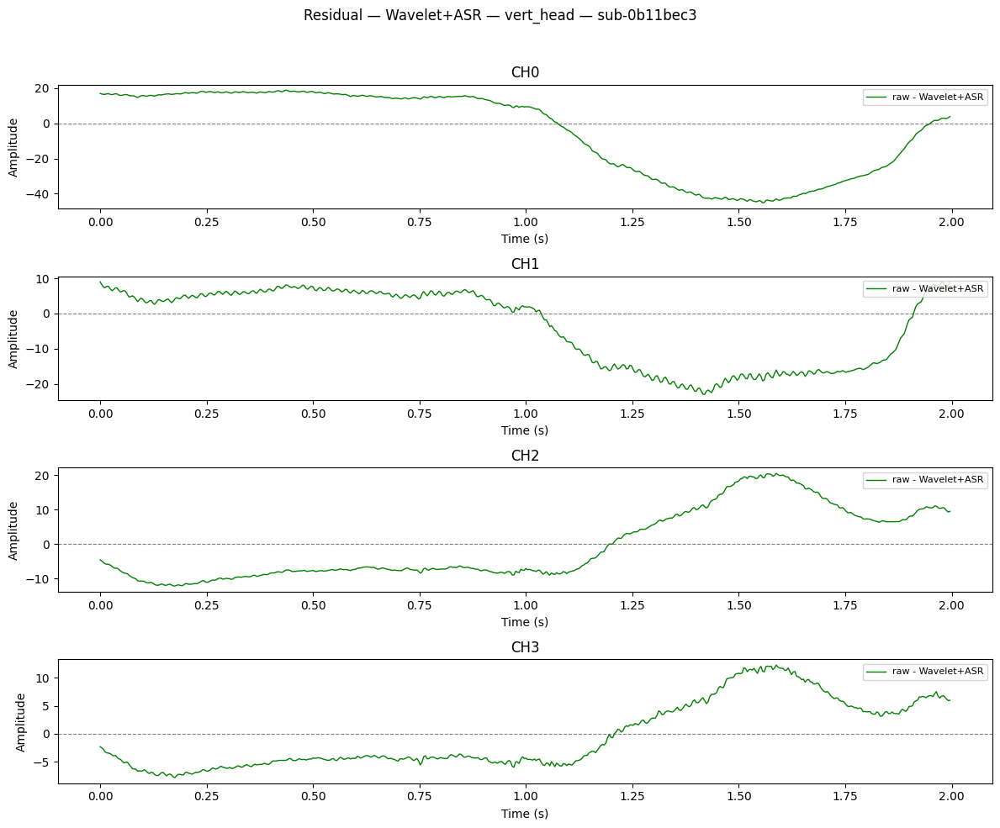

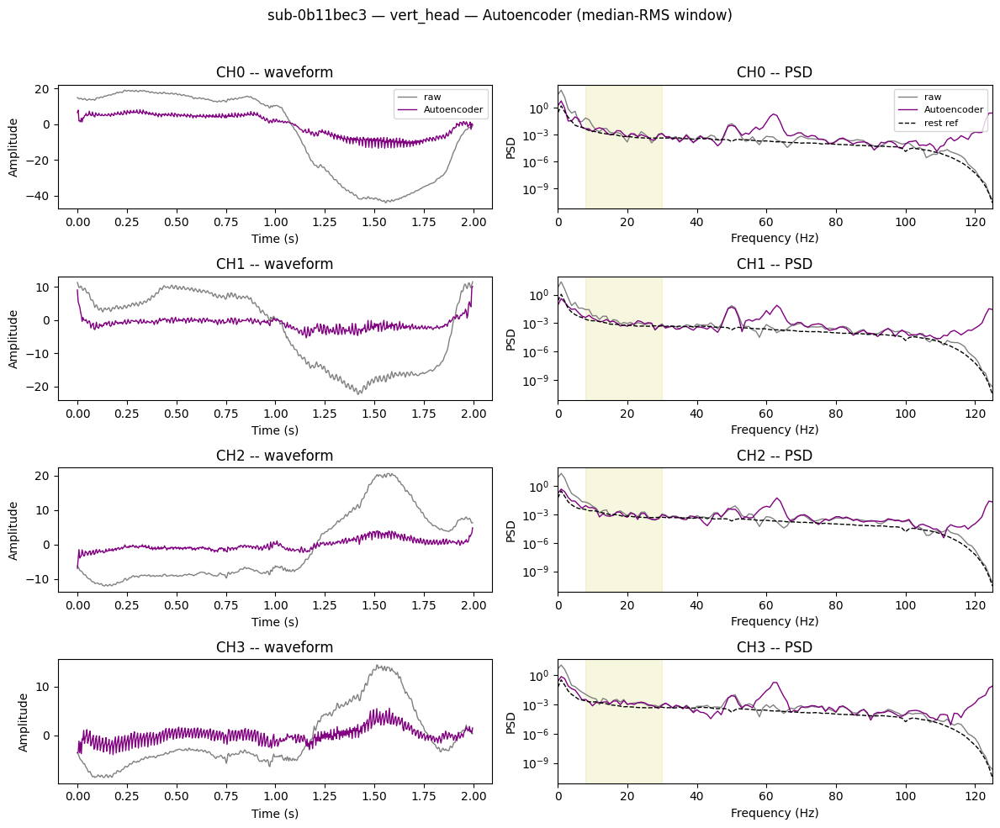

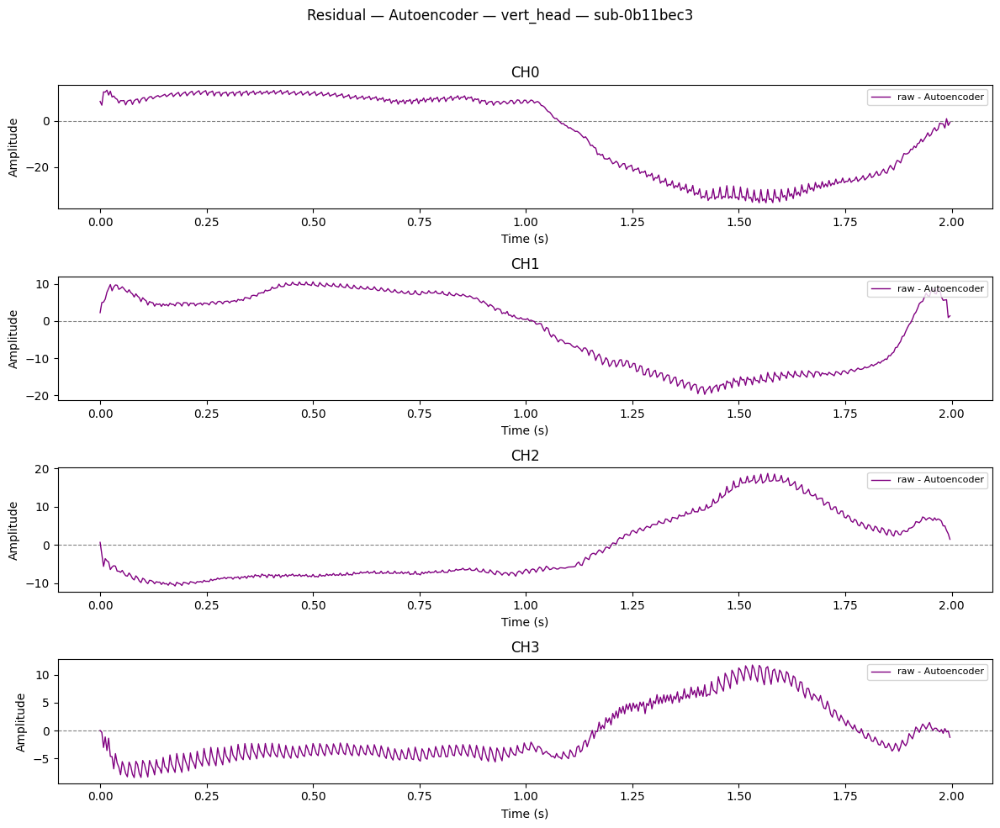

=== Pooled metrics (all subjects) -- vert_head ===


,Artifact-band attenuation (dB),SNR improvement (dB),RMS reduction (dB)
method,,,
Wavelet,0.10,0.10,0.15
ASR,10.79,8.40,12.93
Wavelet+ASR,11.09,8.60,13.61
Autoencoder,12.08,7.94,11.33


In [14]:
# Section 5 -- vert_head: per-method figures for the representative subject.
art = "vert_head"
subj = CONFIG["REPR_SUBJECTS"][0]
if art not in raw_class_windows.get(subj, {}):
    print(f"  ({subj}: no '{art}' windows -- skipped)")
else:
    for method in PLOT_METHODS:        # Wavelet -> ASR -> Wavelet+ASR -> Autoencoder
        plot_method_waveform_psd(subj, art, method)   # Figure A
        plot_method_residual(subj, art, method)       # Figure B

print(f"=== Pooled metrics (all subjects) -- {art} ===")
class_metrics_table(art)

## Section 6 — clench

Per-method comparison for the **clench** artifact (artifact band = 30–99 Hz (high-frequency EMG)). Figure A
(waveform + PSD) and Figure B (residuals) are shown for each representative
subject on its median-RMS window; the pooled metrics table aggregates across all
subjects.

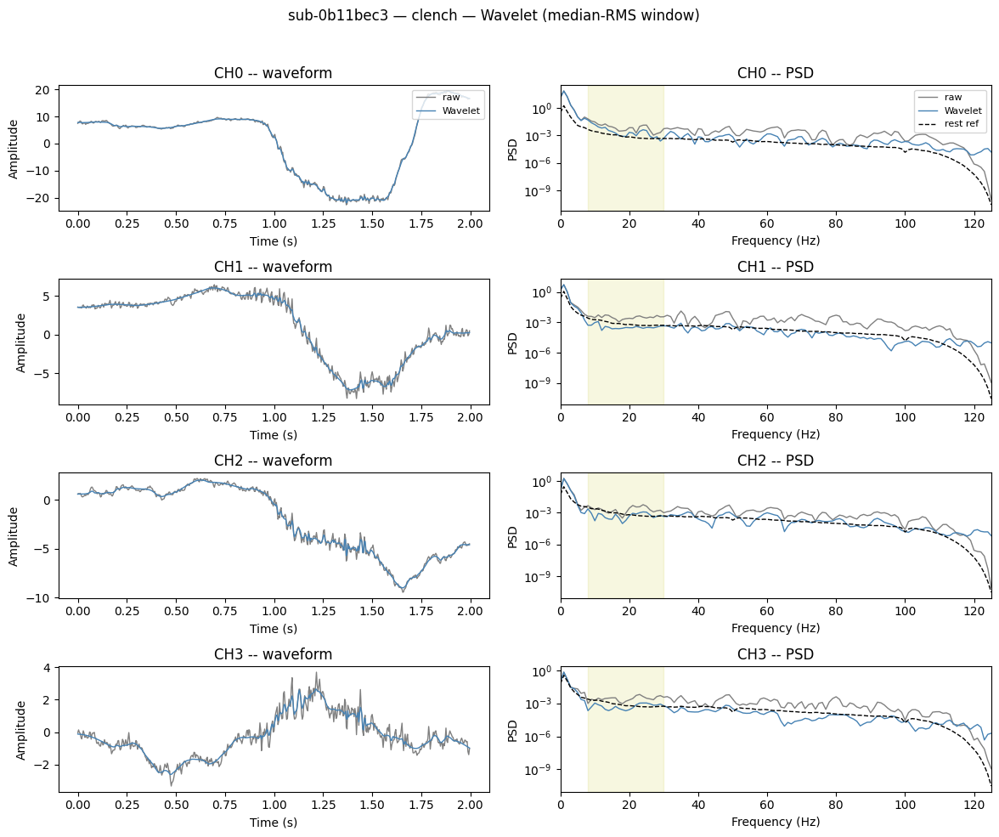

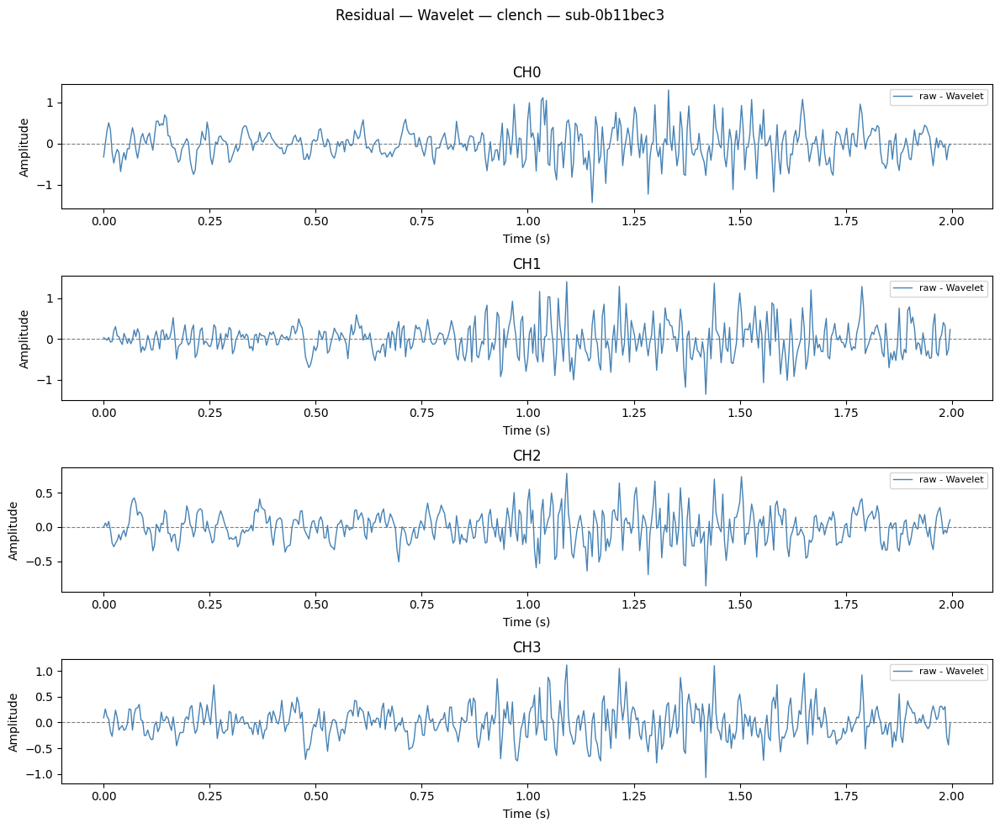

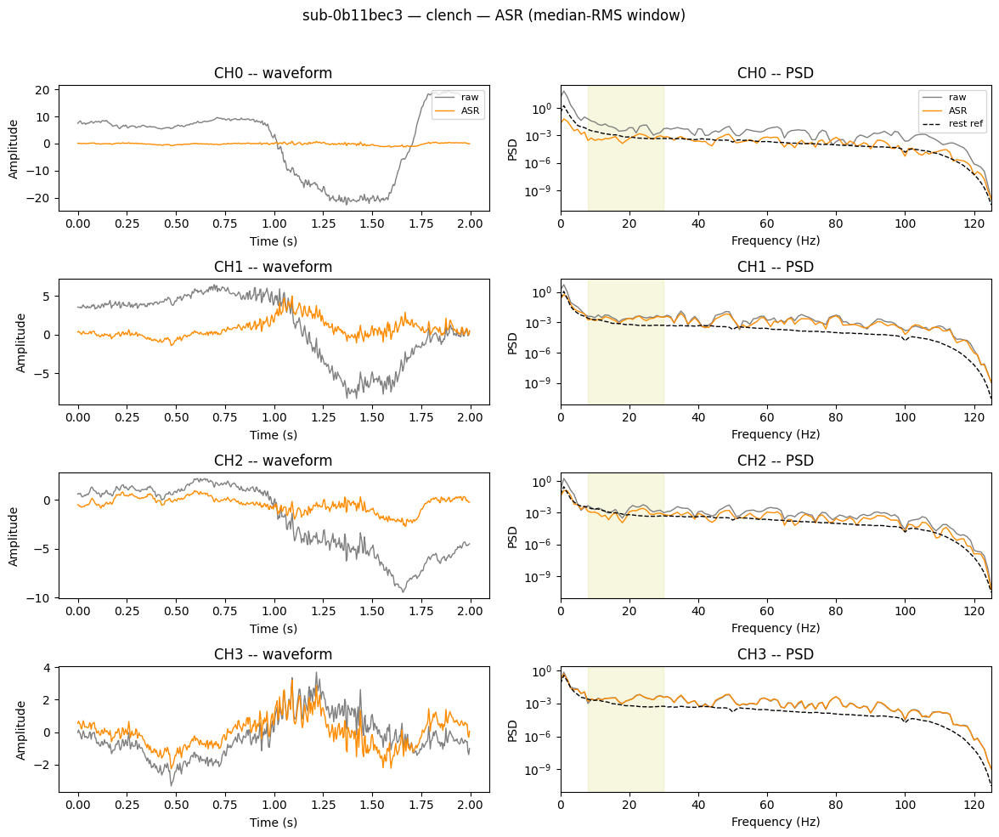

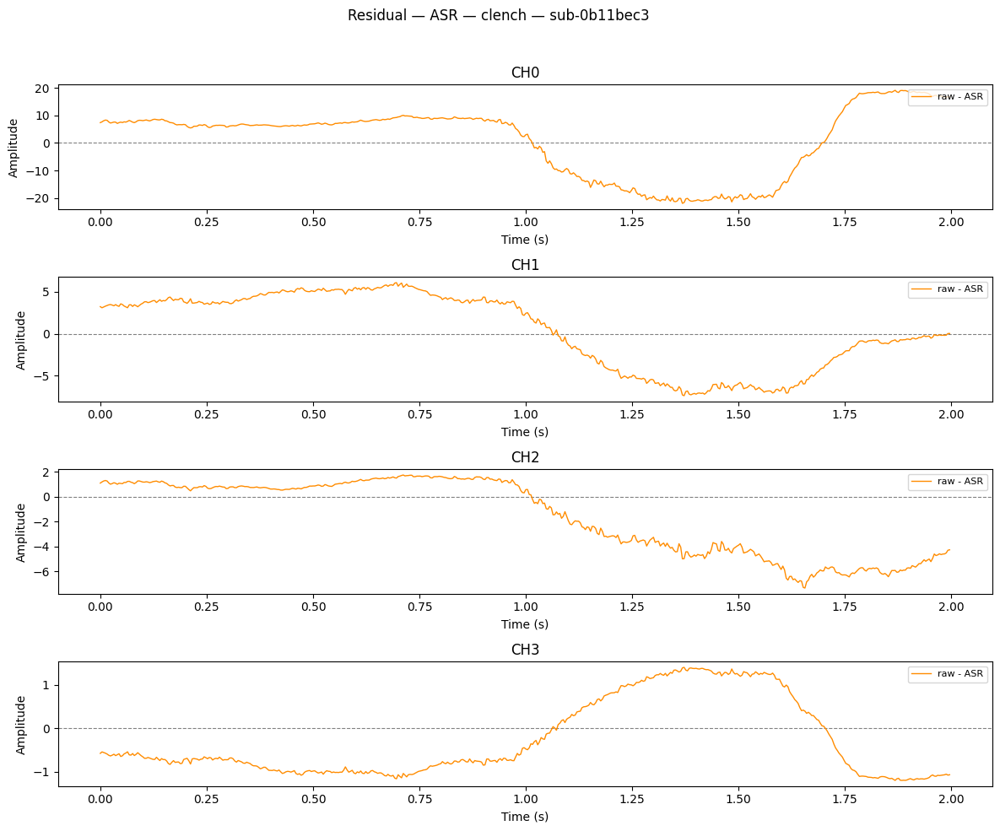

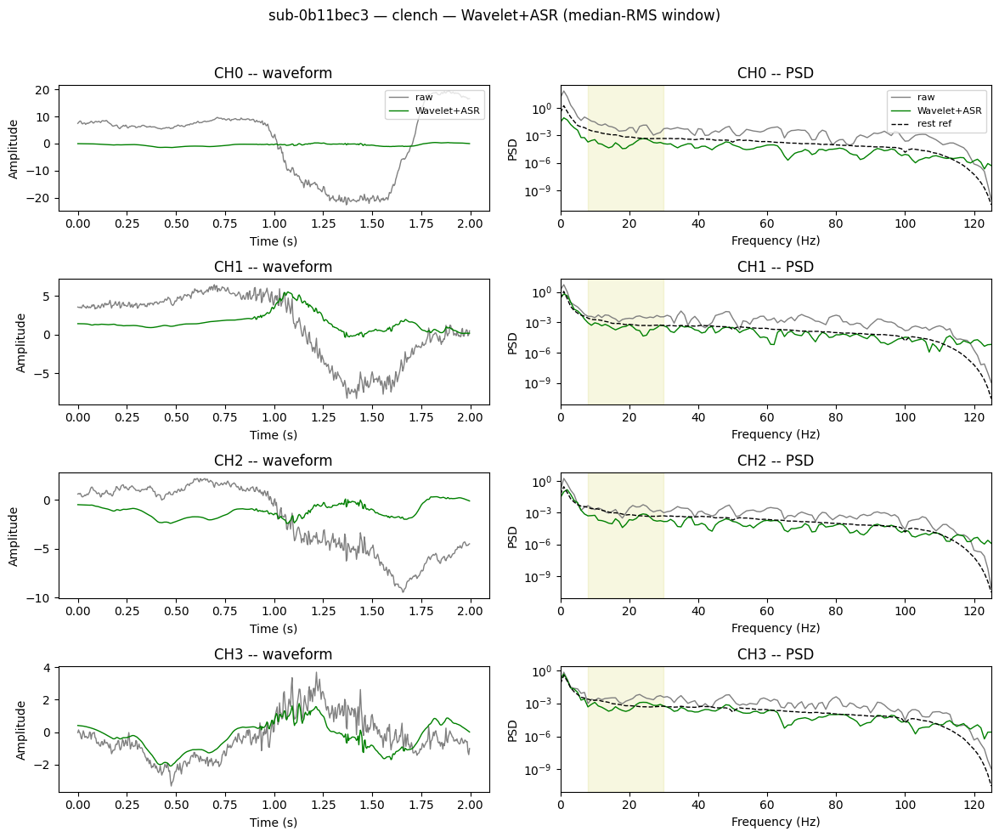

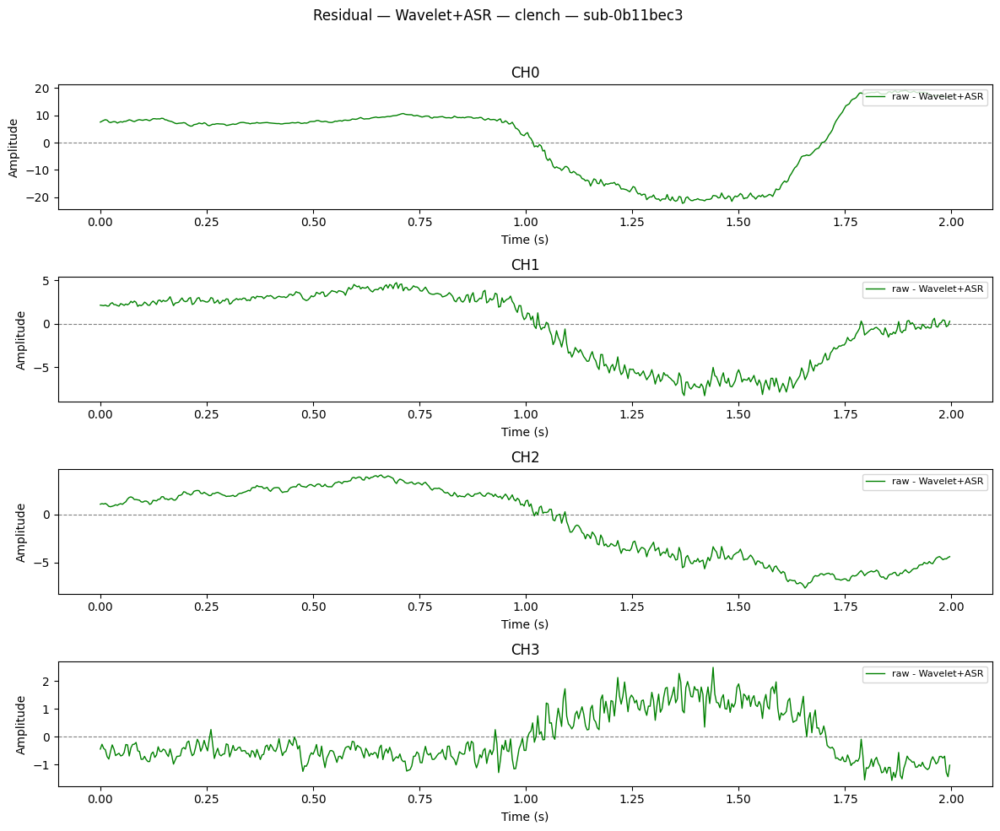

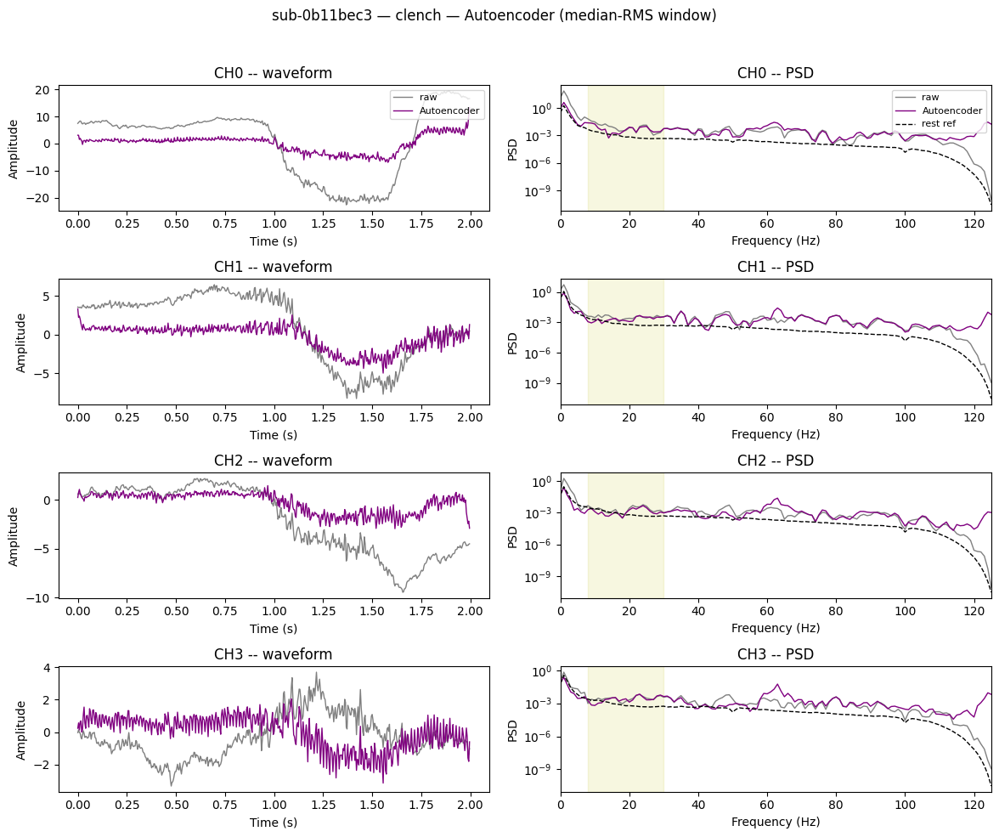

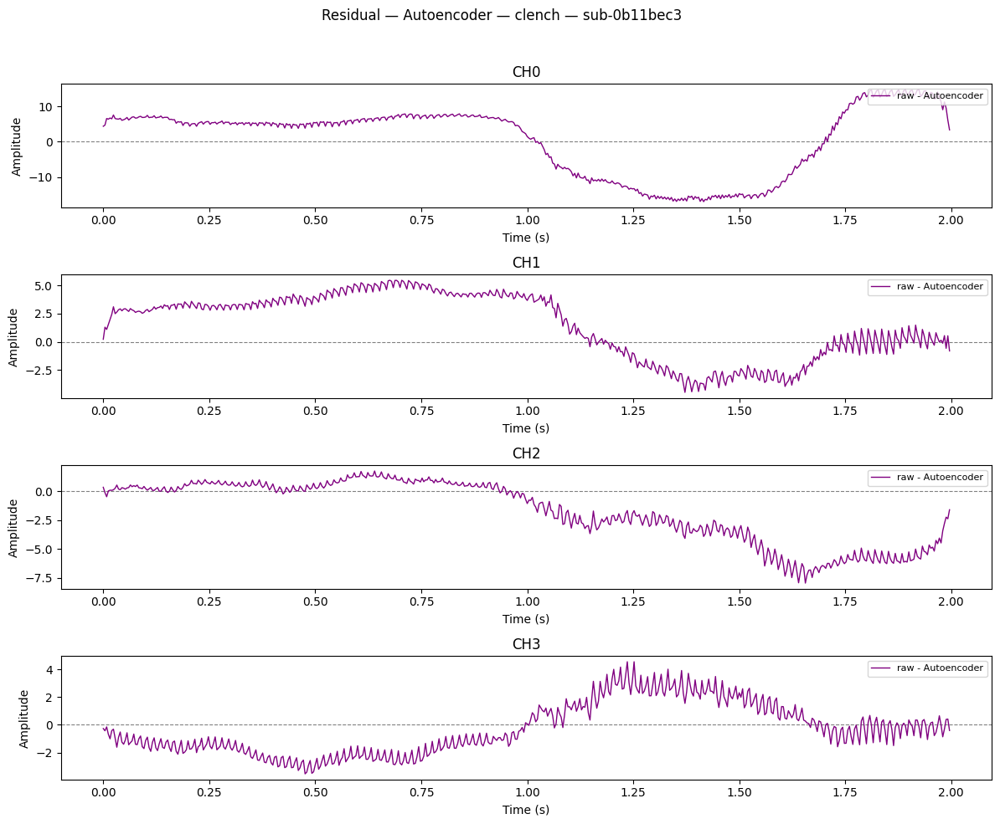

=== Pooled metrics (all subjects) -- clench ===


,Artifact-band attenuation (dB),SNR improvement (dB),RMS reduction (dB)
method,,,
Wavelet,10.00,0.12,0.19
ASR,2.93,9.36,13.43
Wavelet+ASR,12.29,9.73,14.41
Autoencoder,-2.95,7.93,10.94


In [15]:
# Section 6 -- clench: per-method figures for the representative subject.
art = "clench"
subj = CONFIG["REPR_SUBJECTS"][0]
if art not in raw_class_windows.get(subj, {}):
    print(f"  ({subj}: no '{art}' windows -- skipped)")
else:
    for method in PLOT_METHODS:        # Wavelet -> ASR -> Wavelet+ASR -> Autoencoder
        plot_method_waveform_psd(subj, art, method)   # Figure A
        plot_method_residual(subj, art, method)       # Figure B

print(f"=== Pooled metrics (all subjects) -- {art} ===")
class_metrics_table(art)

## Section 7 — Summary metrics and comparison

One table with rows = method × artifact class and columns = the three metrics,
followed by three grouped bar charts (one per metric: x-axis = artifact class,
grouped bars = methods, coloured per `METHOD_COLORS`).

In [16]:
# Section 7 (a) -- Cross-method / cross-class summary table.
rows = []
for m in METHODS:
    for art in ARTIFACT_CLASSES:
        recs = metrics[m][art]
        rows.append({
            "method": METHOD_LABELS[m],
            "artifact_class": art,
            "Artifact-band attenuation (dB)":
                np.mean([r["artifact_band_attenuation_db_mean"] for r in recs]),
            "SNR improvement (dB)":
                np.mean([r["snr_improvement_db_mean"] for r in recs]),
            "RMS reduction (dB)":
                np.mean([r["rms_reduction_db_mean"] for r in recs]),
        })
summary_df = pd.DataFrame(rows).round(2)
print(summary_df.to_string(index=False))

summary_df.to_csv(CONFIG["OUTPUT_DIR"] / "denoising_method_comparison.csv",
                  index=False)
print(f"\nSaved {CONFIG['OUTPUT_DIR'] / 'denoising_method_comparison.csv'}")

     method artifact_class  Artifact-band attenuation (dB)  SNR improvement (dB)  RMS reduction (dB)
    Wavelet          blink                            0.31                  0.12                0.55
    Wavelet      look_left                            0.26                  0.10                0.34
    Wavelet     look_right                            0.28                  0.12                0.35
    Wavelet     horiz_head                            0.20                  0.49                0.72
    Wavelet      vert_head                            0.10                  0.10                0.15
    Wavelet         clench                           10.00                  0.12                0.19
        ASR          blink                            4.20                  1.73                4.81
        ASR      look_left                            7.20                  3.10                8.34
        ASR     look_right                            4.91                  2.15           

### A note on negative artifact-band reduction

Negative artifact-band reduction values are correct and meaningful: they
indicate that the denoising method **increased** power in the artifact frequency
band rather than reducing it. This happens when the method introduces its own
spectral components in that band — most notably the **autoencoder on clench**,
where the decoder learned from a training distribution dominated by
low-frequency ocular artifacts and therefore actively *distorts* the 30–99 Hz
EMG band when applied to a jaw clench. The values below are left unclipped so
this behaviour stays visible.

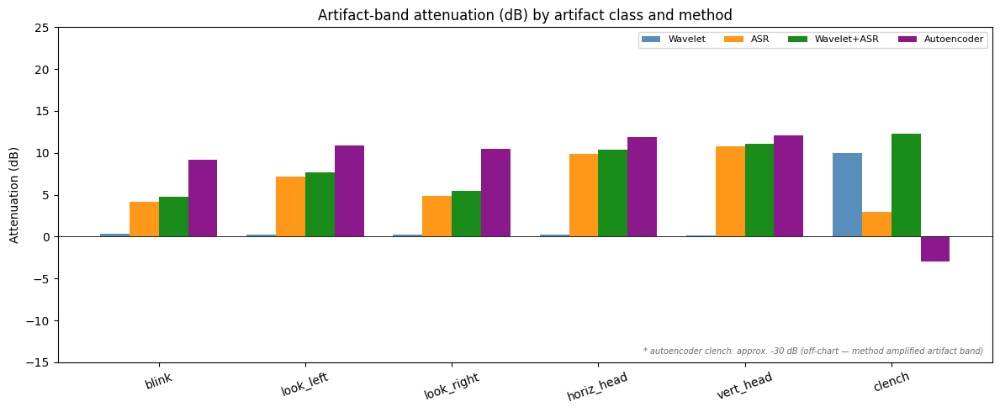

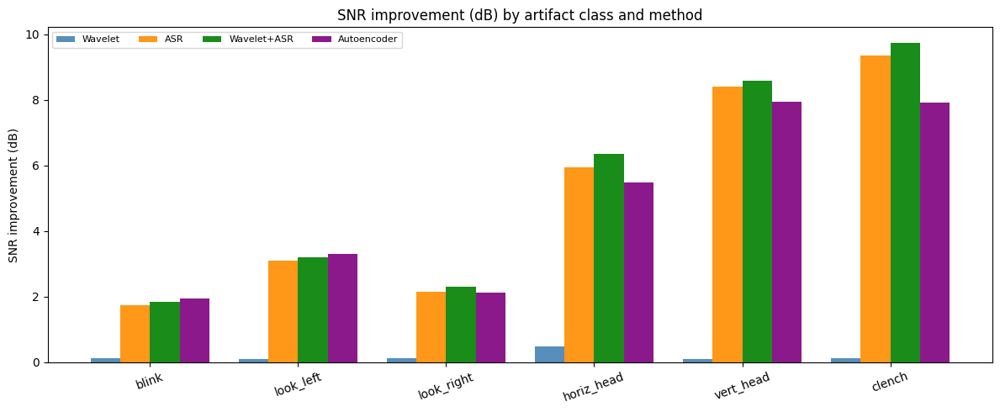

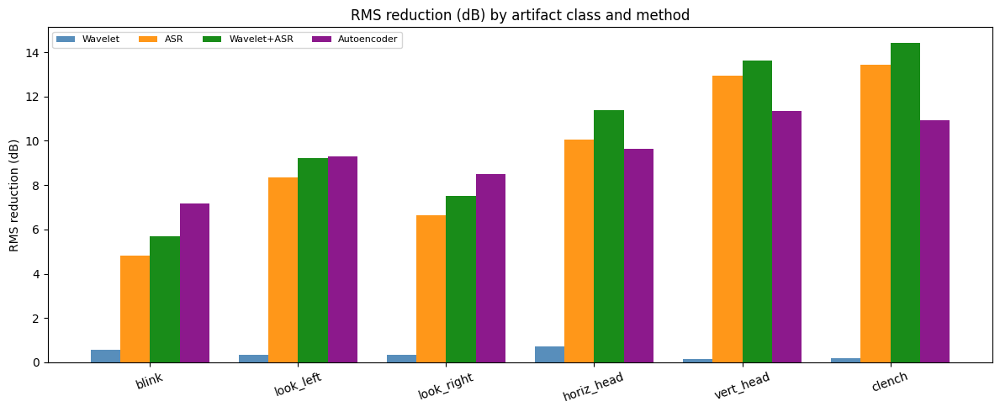

In [17]:
# Section 7 (b) -- Three grouped bar charts (one per metric).
metric_charts = [
    {"key": "artifact_band_attenuation_db",
     "title": "Artifact-band attenuation (dB) by artifact class and method",
     "ylabel": "Attenuation (dB)",
     "ylim": (-15, 25),
     "annotation": "* autoencoder clench: approx. -30 dB "
                   "(off-chart — method amplified artifact band)"},
    {"key": "snr_improvement_db",
     "title": "SNR improvement (dB) by artifact class and method",
     "ylabel": "SNR improvement (dB)",
     "ylim": None,
     "annotation": None},
    {"key": "rms_reduction_db",
     "title": "RMS reduction (dB) by artifact class and method",
     "ylabel": "RMS reduction (dB)",
     "ylim": None,
     "annotation": None},
]
x = np.arange(len(ARTIFACT_CLASSES))
width = 0.8 / len(METHODS)

for chart in metric_charts:
    key = chart["key"]
    fig, ax = plt.subplots(figsize=(12, 5))
    for j, m in enumerate(METHODS):
        vals = [np.mean([r[f"{key}_mean"] for r in metrics[m][art]])
                for art in ARTIFACT_CLASSES]
        offset = (j - (len(METHODS) - 1) / 2) * width
        ax.bar(x + offset, vals, width, color=METHOD_COLORS[m],
               label=METHOD_LABELS[m], alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(ARTIFACT_CLASSES, rotation=20)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel(chart["ylabel"])
    ax.set_title(chart["title"])
    if chart["ylim"] is not None:
        ax.set_ylim(*chart["ylim"])
    if chart["annotation"] is not None:
        ax.text(0.99, 0.02, chart["annotation"], transform=ax.transAxes,
                ha="right", va="bottom", fontsize=7, style="italic", color="dimgray")
    ax.legend(fontsize=8, ncol=len(METHODS))
    fig.tight_layout()
    fig.savefig(CONFIG["OUTPUT_DIR"] /
                f"denoising_{key}_by_method.png", dpi=140)
    plt.show()

## Section 8 — Conclusions

### Wavelet denoising
Standard wavelet denoising with universal thresholding (db4, 5 levels, soft threshold)
operates exclusively on high-frequency detail coefficients. All ocular and head movement
artifacts are low-frequency (0.5–8 Hz) and reside in the approximation coefficients,
which are never thresholded. Wavelet is therefore ineffective for these classes and
serves only as a high-frequency noise smoother. For clench, partial attenuation of
the 30–99 Hz EMG band is observed but the slow baseline drift component is untouched.

### ASR
ASR with k=12 (calibrated on the subject's own rest baseline) effectively removes
large-amplitude low-frequency artifacts via covariance subspace reconstruction.
Blink, look_left, look_right and head movement residuals show recognisable artifact
morphology confirming genuine artifact extraction. Performance degrades for small-
amplitude artifacts (look_right) where the signal falls below the covariance threshold.
For clench, ASR removes the slow drift component but leaves the broadband EMG content
unchanged, since EMG oscillations remain within the clean covariance subspace boundary.

### Wavelet + ASR cascade
Marginally better than ASR alone for large-amplitude artifacts (head movements, blink)
where wavelet smoothing before ASR reduces noise floor. For small-amplitude artifacts
(look_right) the cascade fails silently: wavelet reduces amplitude below ASR threshold,
causing ASR to produce no correction.

### Autoencoder
The residual-learning 1D-CNN autoencoder performs best on blink and saccade artifacts,
where the learned subtraction template closely matches the artifact morphology. For head
movements results are comparable to ASR. For jaw clench, the autoencoder fails: trained
on a dataset dominated by low-frequency ocular and motion artifacts, the decoder learned
a low-frequency subtraction template. Applied to clench — whose dominant component is
30–99 Hz broadband EMG — the decoder subtracts a mismatched template and actively
increases artifact-band power (negative artifact-band attenuation dB). This is a known
limitation of class-agnostic autoencoders on spectrally heterogeneous artifact datasets.
A class-conditioned architecture or separate per-class models would be required to
address this limitation.

### Hardware constraint
All methods are fundamentally limited by the 4-channel frontal electrode placement.
Artifact and neural signal overlap in the 0.5–8 Hz band with no spatial separation
available. Dedicated EOG reference electrodes, increased channel count, or extended
temporal context would be required for artifact-specific source separation.